# NLP Midterm Project
## Text Analysis, Sentiment Analysis and Topic Modeling

**Course:** Data Mining  |  **Student:** Amantur Sharabidinov  |  **Group:** MATDAIS-24

---
### Project idea in one paragraph
We build a small NLP system that processes raw text, turns it into numbers, detects sentiment, discovers hidden
topics, visualises the text space, and extracts and links named entities. Following the instructor's clarification,
the work is done on **two datasets**, each chosen for the task it suits best:

| | Dataset 1 — hotel reviews | Dataset 2 — news articles |
|---|---|---|
| Source | TripAdvisor, *Phoenix Hotel, London* (scraped with the Easy Scraper extension) | The Guardian Open Platform API |
| Size | 970 English reviews | 478 articles, 6 sections |
| Why this dataset | Opinionated text → ideal for **sentiment analysis** | Long, topic-rich, full of names → ideal for **LDA, t-SNE and NER** |
| Modules | 1 (preprocessing), 2 (vectorization), 3 (sentiment) | 1 (preprocessing), 4 (LDA), 5 (t-SNE), 6 (NER + linking) |

The same preprocessing function (Module 1) is reused for both datasets, and the final section compares what we learned
from the two very different kinds of text.

### Contents
0. Setup
1. Module 1 — Text preprocessing and tokenization
2. Module 2 — Text vectorization (BoW, TF-IDF, Word2Vec, BERT)
3. Module 3 — Sentiment analysis
4. Module 4 — Topic modeling with LDA
5. Module 5 — t-SNE visualization
6. Module 6 — Named Entity Recognition and Entity Linking
7. General conclusion
8. Preparation for the defense (answers to the 14 questions)
9. Sources and academic integrity

> **Originality note.** The pipeline, the thresholds, the topic naming, the evaluation experiments and the entity-linking
> approach were designed and implemented specifically for these two datasets. Libraries and external resources are listed in section 9.

## 0. Setup

Install once (in a terminal or a notebook cell):
```
pip install pandas numpy matplotlib seaborn scikit-learn spacy gensim wordcloud vaderSentiment textblob nltk rapidfuzz pycountry requests torch transformers
python -m spacy download en_core_web_sm
```
Input files (created by `00_data_collection.ipynb` and `01_prepare_reviews.ipynb`): `data/reviews.csv`, `data/news.csv`.

In [1]:
import re, html, json, time, random, warnings, collections, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

import sklearn, spacy, gensim
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

def save_fig(name):
    """Save the current matplotlib figure into ./figures (deliverable: visualizations)."""
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| spaCy", spacy.__version__, "| gensim", gensim.__version__)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    raise SystemExit("spaCy model missing. Run:  python -m spacy download en_core_web_sm")
print("spaCy model:", nlp.meta["name"], nlp.meta["version"])

pandas 2.2.3 | scikit-learn 1.6.1 | spaCy 3.8.16 | gensim 4.4.0
spaCy model: core_web_sm 3.8.0


spaCy model: core_web_sm 3.8.0


---
# Module 1. Text Preprocessing and Tokenization

**Goal:** turn raw, messy text into clean lists of meaningful words (lemmas) that the later modules can use.

**Plan:** (1.1) load and explore → (1.2) clean → (1.3) tokenize → (1.4) remove stop words → (1.5) lemmatize →
(1.6) the required `preprocess_text` function → (1.7) apply to both datasets.

## 1.1 Load the datasets with Pandas and explore them

In [3]:
reviews = pd.read_csv(DATA / "reviews.csv")
news = pd.read_csv(DATA / "news.csv")

# For news we analyse headline + body as one document
news["text"] = news["headline"].fillna("").str.rstrip(".!? ") + ". " + news["body_text"].fillna("")

def overview(df, name):
    print(f"===== {name} =====")
    print(f"records: {len(df)} | columns: {df.shape[1]} | fully duplicated rows: {df.duplicated().sum()}")
    info = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing %": (df.isna().mean() * 100).round(1),
        "unique values": df.nunique(),
    })
    display(info)

overview(reviews, "Dataset 1: hotel reviews")
display(reviews.head(3))

===== Dataset 1: hotel reviews =====
records: 970 | columns: 12 | fully duplicated rows: 0


,dtype,missing,missing %,unique values
review_id,int64,0,0.0,970
tripadvisor_id,int64,0,0.0,970
hotel,object,0,0.0,1
rating_group,object,0,0.0,2
title,object,0,0.0,897
body,object,17,1.8,951
text,object,0,0.0,970
date_of_stay,object,10,1.0,178
year,float64,10,1.0,22
trip_type,object,45,4.6,5


,review_id,tripadvisor_id,hotel,rating_group,title,body,text,date_of_stay,year,trip_type,translated,source_url
0,1,1084152545,"Phoenix Hotel, London",1-3,Moldy rat hole with lousy breakfast and unprofessional staff,It was a lousy moldy rat hole. We made a mistake picking up the hotel that seemed to have such a nice loca...,Moldy rat hole with lousy breakfast and unprofessional staff. It was a lousy moldy rat hole. We made a mis...,2026-10,2026.0,with family,False,https://www.tripadvisor.co.uk/ShowUserReviews-g186338-d192081-r1084152545-Phoenix_Hotel-London_England.html
1,2,1081910656,"Phoenix Hotel, London",1-3,Do not recommend,"We expect hotel rooms in Europe to be small, but this was exceptionally small. The bathroom was smaller th...","Do not recommend. We expect hotel rooms in Europe to be small, but this was exceptionally small. The bathr...",2026-10,2026.0,as a couple,False,https://www.tripadvisor.co.uk/ShowUserReviews-g186338-d192081-r1081910656-Phoenix_Hotel-London_England.html
2,3,1073258213,"Phoenix Hotel, London",1-3,Too hot,"The hotel was nice, the room beautiful and clean with the essentials; it was cleaned every morning and the...","Too hot. The hotel was nice, the room beautiful and clean with the essentials; it was cleaned every mornin...",2026-08,2026.0,with family,False,https://www.tripadvisor.co.uk/ShowUserReviews-g186338-d192081-r1073258213-Phoenix_Hotel-London_England.html


In [4]:
overview(news.drop(columns=["text"]), "Dataset 2: news articles")
display(news[["doc_id", "section", "date", "headline", "byline"]].head(3))

===== Dataset 2: news articles =====
records: 478 | columns: 9 | fully duplicated rows: 0


,dtype,missing,missing %,unique values
doc_id,int64,0,0.0,478
article_id,object,0,0.0,478
section,object,0,0.0,6
date,object,0,0.0,49
headline,object,0,0.0,478
trail_text,object,0,0.0,478
byline,object,19,4.0,239
body_text,object,0,0.0,478
url,object,0,0.0,478


,doc_id,section,date,headline,byline
0,1,politics,2026-10-31,A world-first focus on long-term outcomes could transform UK government – or create new spending fights,Peter Walker Senior political correspondent
1,2,politics,2026-10-31,Starmer says UK must get closer to Europe as US relationship changes,Kevin Rawlinson
2,3,politics,2026-10-31,Streeting says he began stockpiling food weeks ago amid rising threat to UK,Kevin Rawlinson


**Reading the tables.**
* *Reviews:* 970 records. Missing values exist only in auxiliary columns (`date_of_stay`/`year` for a few old reviews, `trip_type`) —
  none in the text columns. `rating_group` (`1-3` / `4-5`) is the only quality label we have; it will be used later to validate sentiment analysis.
* *News:* 478 articles; the only missing values are in `byline` (some Guardian articles have no named author), which we do not need.

Next we look at the shape of the data: class balance and text lengths.

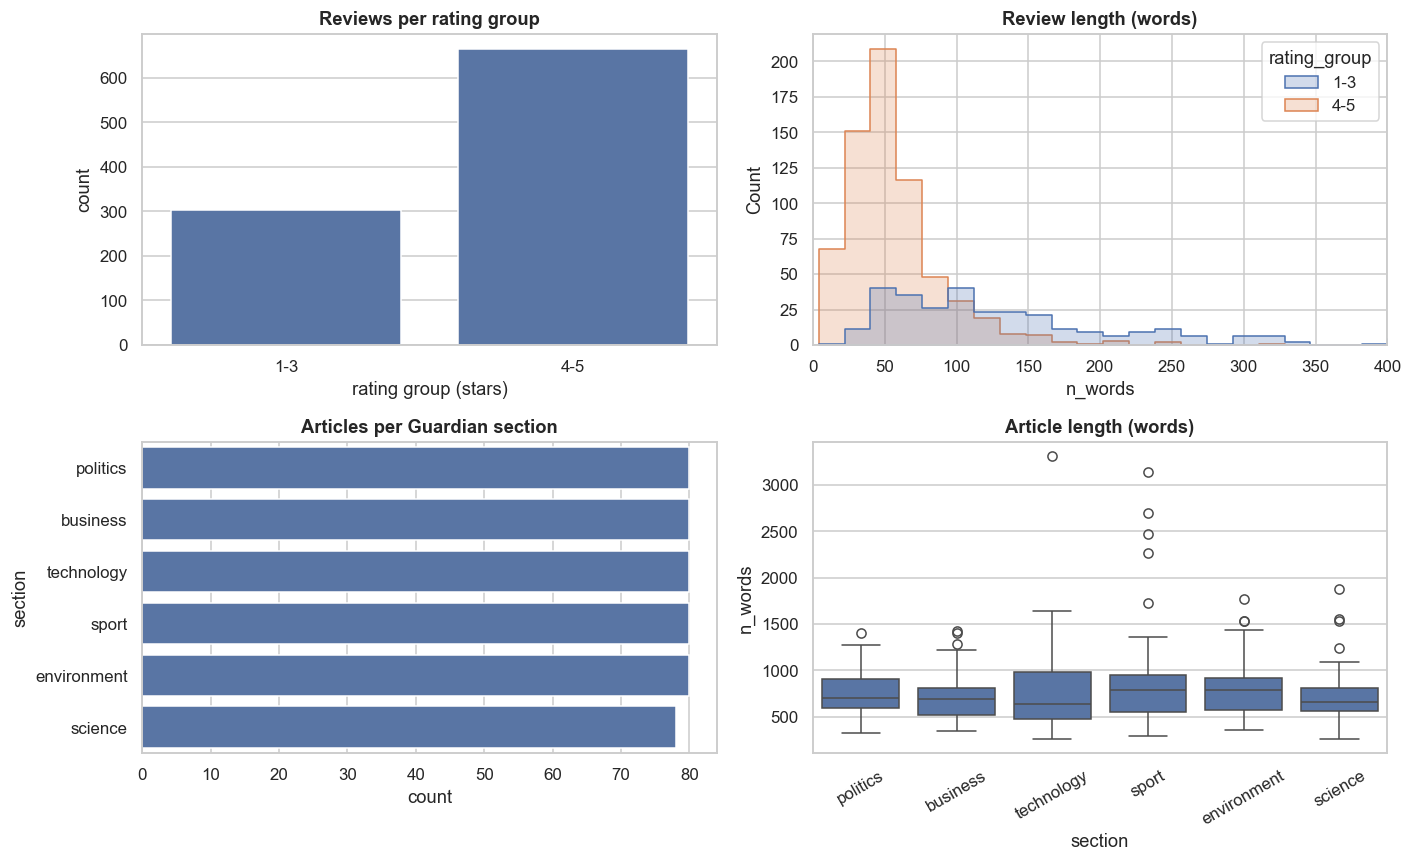

Median length: reviews = 59 words | news = 705 words


In [5]:
reviews["n_words"] = reviews["text"].str.split().str.len()
news["n_words"] = news["text"].str.split().str.len()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.countplot(data=reviews, x="rating_group", order=["1-3", "4-5"], ax=axes[0, 0])
axes[0, 0].set_title("Reviews per rating group"); axes[0, 0].set_xlabel("rating group (stars)")
sns.histplot(data=reviews, x="n_words", hue="rating_group", bins=40, element="step", ax=axes[0, 1])
axes[0, 1].set_title("Review length (words)"); axes[0, 1].set_xlim(0, 400)
order = news["section"].value_counts().index
sns.countplot(data=news, y="section", order=order, ax=axes[1, 0])
axes[1, 0].set_title("Articles per Guardian section")
sns.boxplot(data=news, x="section", y="n_words", order=order, ax=axes[1, 1])
axes[1, 1].set_title("Article length (words)"); axes[1, 1].tick_params(axis="x", rotation=30)
plt.tight_layout(); save_fig("01_data_exploration"); plt.show()

print("Median length: reviews =", int(reviews.n_words.median()), "words | news =", int(news.n_words.median()), "words")

**Observation.** Reviews are short (median ≈ 60 words), articles are ~12× longer (median ≈ 700 words). That difference
will matter later: short noisy texts are harder for topic models, long texts make vectors denser.
Reviews are imbalanced towards `4-5` — the hotel is mostly well rated (see the limitation in `DATASET_DESCRIPTION.md`).

## 1.2 Clean the text

Cleaning removes everything that carries no meaning for the models:
HTML tags and entities, URLs, punctuation, digits, symbols (£, $, emoji), repeated spaces; and converts to lowercase.
Accented letters are reduced to plain ASCII (*café → cafe*). We keep apostrophes inside words (*don't*, *hotel's*) so the tokenizer can split contractions correctly.

In [6]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
HTML_RE = re.compile(r"<[^>]+>")

def clean_text(text):
    """Lowercase; remove HTML, URLs, punctuation, digits, symbols and extra spaces."""
    text = html.unescape(str(text))                 # &amp; -> &
    text = HTML_RE.sub(" ", text)                   # <p>, <br/> ...
    text = URL_RE.sub(" ", text)                    # http://..., www....
    text = text.lower()
    text = text.replace("’", "'").replace("‘", "'")
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()   # café -> cafe, drops £ € emoji
    text = re.sub(r"[^a-z\s']", " ", text)          # keep letters, spaces, apostrophes
    text = re.sub(r"'(?![a-z])|(?<![a-z])'", " ", text)   # drop quotes that are not inside a word
    return re.sub(r"\s+", " ", text).strip()        # collapse spaces

demo = "Great <b>location</b>!!! Visit https://example.com — we paid £120/night & loved it :)   Don't miss the café."
print("BEFORE:", demo)
print("AFTER :", clean_text(demo))

BEFORE: Great <b>location</b>!!! Visit https://example.com — we paid £120/night & loved it :)   Don't miss the café.
AFTER : great location visit we paid night loved it don't miss the cafe


## 1.3 – 1.5 Tokenization, stop-word removal and lemmatization step by step

We use **spaCy**, which performs tokenization, part-of-speech tagging and lemmatization in one pipeline.
Below, one real review goes through every stage, so each step is visible.

In [7]:
sample = reviews.loc[reviews["rating_group"] == "1-3", "text"].iloc[3]
cleaned = clean_text(sample)
doc = nlp(cleaned)

stage_tokens = [t.text for t in doc]
stage_nostop = [t.text for t in doc if not t.is_stop and not t.is_space]
stage_lemmas = [t.lemma_ for t in doc if not t.is_stop and t.lemma_.isalpha()]
print("spaCy stop-word list size:", len(nlp.Defaults.stop_words), "| negations included:", sorted({"not", "no", "never"} & nlp.Defaults.stop_words))

print("RAW REVIEW :", sample[:260], "...\n")
print("CLEANED    :", cleaned[:260], "...\n")
steps = pd.DataFrame({
    "step": ["1. tokenization", "2. stop words removed", "3. lemmas (alphabetic only)"],
    "tokens": [len(stage_tokens), len(stage_nostop), len(stage_lemmas)],
    "first 14 items": [stage_tokens[:14], stage_nostop[:14], stage_lemmas[:14]],
})
display(steps)

spaCy stop-word list size: 326 | negations included: ['never', 'no', 'not']
RAW REVIEW : Superb location, great staff, rooms needs upgraded aircon/fan set-up. Reception staff day and night were very friendly and helpful , first impressions excellent The room was spotlessly clean. One small thing - the clingy shower curtains should really be phased ...

CLEANED    : superb location great staff rooms needs upgraded aircon fan set up reception staff day and night were very friendly and helpful first impressions excellent the room was spotlessly clean one small thing the clingy shower curtains should really be phased out the ...



,step,tokens,first 14 items
0,1. tokenization,154,"[superb, location, great, staff, rooms, needs, upgraded, aircon, fan, set, up, reception, staff, day]"
1,2. stop words removed,89,"[superb, location, great, staff, rooms, needs, upgraded, aircon, fan, set, reception, staff, day, night]"
2,3. lemmas (alphabetic only),89,"[superb, location, great, staff, room, needs, upgrade, aircon, fan, set, reception, staff, day, night]"


**What happened at each step**
* **Tokenization** split the string into word-level units (and separated contractions such as *do* + *n't*).
* **Stop-word removal** dropped very frequent function words (*the, was, and, in, very…*) that appear in every text and say nothing about its content.
  spaCy's list has ~320 words; it also contains negations (*not, no, never*). That is acceptable for topic and keyword analysis,
  but would harm sentiment analysis — which is why Module 3 works on the **raw** text, not on lemmas.
* **Lemmatization** replaced each word by its dictionary form (*rooms → room, was → be, stayed → stay*), so that different forms of the same word are counted together.

**Stemming vs. lemmatization** (a defense question): a stemmer chops suffixes by rules and may produce non-words;
a lemmatizer uses a dictionary and the part of speech and returns real words.

In [8]:
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()
words = ["studies", "studying", "technologies", "better", "was", "mice", "feet", "organization", "caring", "running"]
cmp = pd.DataFrame({
    "word": words,
    "Porter stem": [stemmer.stem(w) for w in words],
    "spaCy lemma": [nlp(w)[0].lemma_ for w in words],
})
display(cmp.T)

,0,1,2,3,4,5,6,7,8,9
word,studies,studying,technologies,better,was,mice,feet,organization,caring,running
Porter stem,studi,studi,technolog,better,wa,mice,feet,organ,care,run
spaCy lemma,study,study,technology,well,be,mouse,foot,organization,care,run


*studies → studi* and *technologies → technolog* are not words; the lemmatizer returns *study* and *technology*, and also handles irregular forms (*mice → mouse*, *feet → foot*, *was → be*) that a stemmer cannot.
We therefore use lemmatization throughout the project.

## 1.6 The required text-processing function

> *Implement a function that tokenizes the text, removes stop words, replaces each remaining token with its lemma,
> discards lemmas containing non-alphabetical characters, and returns the remaining lemmas as a list of strings.*

`preprocess_text` does exactly this. `preprocess_corpus` is the same logic running on many texts at once with
`nlp.pipe` (much faster); it adds two optional filters used later: a minimum lemma length and extra domain stop words.

In [9]:
def _lemmas(doc, extra_stopwords=frozenset(), min_len=1):
    return [
        tok.lemma_
        for tok in doc
        if not tok.is_stop                       # remove stop words
        and tok.lemma_.isalpha()                 # discard lemmas with non-alphabetical characters
        and len(tok.lemma_) >= min_len
        and tok.lemma_ not in extra_stopwords
    ]

def preprocess_text(text, extra_stopwords=(), min_len=1):
    """Tokenize -> remove stop words -> lemmatize -> keep alphabetic lemmas. Returns a list of strings."""
    doc = nlp(clean_text(text))
    return _lemmas(doc, frozenset(extra_stopwords), min_len)

def preprocess_corpus(texts, extra_stopwords=(), min_len=3, batch_size=64):
    """Fast version of preprocess_text for many texts."""
    extra = frozenset(extra_stopwords)
    cleaned_texts = (clean_text(t) for t in texts)
    return [_lemmas(d, extra, min_len) for d in nlp.pipe(cleaned_texts, batch_size=batch_size, disable=["parser", "ner"])]

# --- the example from the assignment ---
example_in = "The students are studying different technologies!"
example_out = preprocess_text(example_in)
print("Input :", example_in)
print("Output:", example_out)
assert example_out == ["student", "study", "different", "technology"], "unexpected output"
print("✔ matches the expected result")

Input : The students are studying different technologies!
Output: ['student', 'study', 'different', 'technology']
✔ matches the expected result


## 1.7 Apply the function to both datasets
We keep lemmas of at least 3 letters (single letters and 2-letter fragments such as *tv*, *ok* add noise).

In [10]:
t0 = time.time()
reviews["tokens"] = preprocess_corpus(reviews["text"], min_len=3)
news["tokens"] = preprocess_corpus(news["text"], min_len=3)
print(f"processed {len(reviews)} reviews and {len(news)} articles in {time.time() - t0:.1f}s")

def token_stats(series, name):
    counts = collections.Counter(w for toks in series for w in toks)
    lens = series.map(len)
    return {"dataset": name, "documents": len(series), "tokens (total)": int(lens.sum()),
            "tokens / doc (mean)": round(lens.mean(), 1), "vocabulary size": len(counts),
            "words used once": sum(1 for c in counts.values() if c == 1)}

display(pd.DataFrame([token_stats(reviews["tokens"], "reviews"), token_stats(news["tokens"], "news")]).set_index("dataset"))

print("\nReview example:\n ", reviews["text"].iloc[1][:200], "\n ->", reviews["tokens"].iloc[1][:20])
print("\nNews example:\n ", news["headline"].iloc[1], "\n ->", news["tokens"].iloc[1][:20])

processed 970 reviews and 478 articles in 64.2s


,documents,tokens (total),tokens / doc (mean),vocabulary size,words used once
dataset,,,,,
reviews,970,38368,39.6,3563,1709
news,478,181621,380.0,16676,6764



Review example:
  Do not recommend. We expect hotel rooms in Europe to be small, but this was exceptionally small. The bathroom was smaller than that on a cruise ship. When we first walked in, the room smelled like sti 
 -> ['recommend', 'expect', 'hotel', 'room', 'europe', 'small', 'exceptionally', 'small', 'bathroom', 'small', 'cruise', 'ship', 'walk', 'room', 'smell', 'like', 'stinky', 'foot', 'hot', 'like']

News example:
  Starmer says UK must get closer to Europe as US relationship changes 
 -> ['starmer', 'say', 'close', 'europe', 'relationship', 'change', 'european', 'nation', 'draw', 'close', 'reliable', 'partner', 'keir', 'starmer', 'say', 'significant', 'political', 'intervention', 'leave', 'prime']


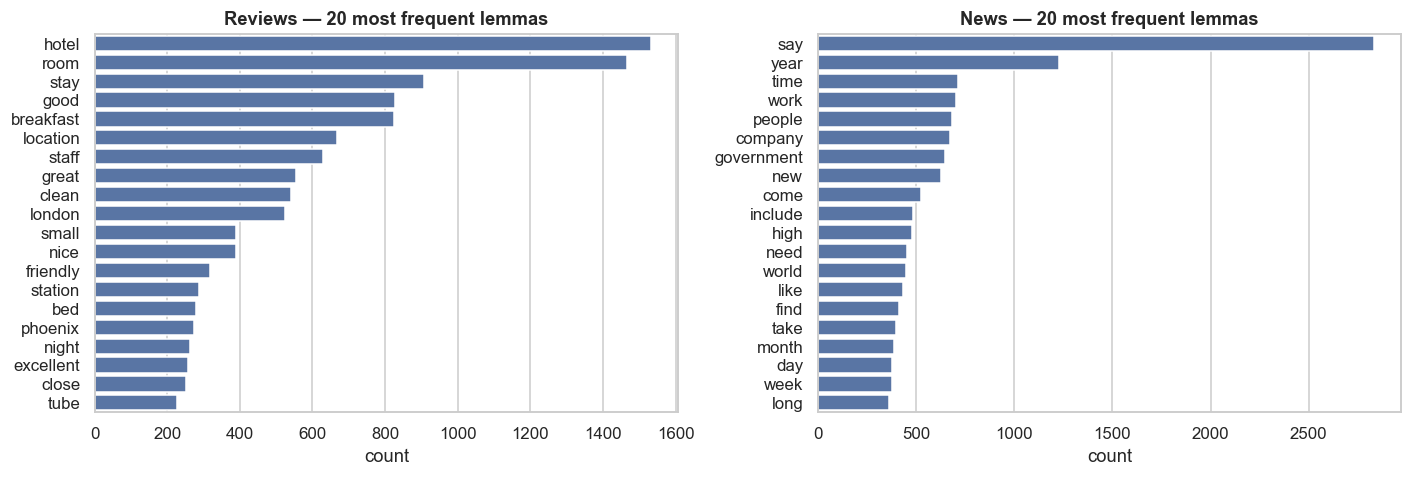

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, series, title in [(axes[0], reviews["tokens"], "Reviews — 20 most frequent lemmas"),
                          (axes[1], news["tokens"], "News — 20 most frequent lemmas")]:
    top = collections.Counter(w for toks in series for w in toks).most_common(20)
    sns.barplot(x=[c for _, c in top], y=[w for w, _ in top], ax=ax, color=sns.color_palette()[0])
    ax.set_title(title); ax.set_xlabel("count")
plt.tight_layout(); save_fig("01_top_lemmas"); plt.show()

**Result of Module 1.** Reviews are dominated by hotel-specific words (*room, hotel, staff, location, stay, breakfast, clean…*) — this vocabulary is what a sentiment or aspect analysis needs.
News lemmas are dominated by reporting verbs and generic words (*say, year, time, people, government…*), which carry little topical information.
This is exactly why topic modeling (Module 4) will add a second layer of filtering (`max_df`, extra stop words).

---
# Module 2. Text Vectorization (dataset 1 — hotel reviews)

Models cannot read words; they need numbers. We build four representations of the **same 970 reviews** and compare them:

| # | Method | Idea | Output |
|---|---|---|---|
| 1 | CountVectorizer (Bag of Words) | count how many times each word occurs | sparse matrix, 1 column per word |
| 2 | TF-IDF | counts re-weighted: frequent-in-document and rare-in-corpus words matter most | sparse matrix, 1 column per word |
| 3 | Word2Vec | dense word vectors learned from the contexts words appear in; a document = mean of its word vectors | dense, 100 dimensions |
| 4 | BERT | contextual sentence embeddings from a pre-trained transformer (as requested by the instructor) | dense, 768 dimensions |

BoW, TF-IDF and Word2Vec use the lemmas from Module 1. BERT is applied to the **original text**, because it is trained on natural sentences
(word order, punctuation, even stop words give it context) and has its own sub-word tokenizer.

In [12]:
docs = reviews["tokens"].map(" ".join)       # lemmas joined back into strings for the sklearn vectorizers
y = (reviews["rating_group"] == "4-5").astype(int).values   # used later to compare representations

## 2.1 CountVectorizer — Bag of Words
Each review becomes a row of word counts; the whole corpus becomes a **document-term matrix**.
`min_df=3` ignores words that occur in fewer than 3 reviews (typos and one-off words).

In [13]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cv = CountVectorizer(min_df=3)
X_bow = cv.fit_transform(docs)
terms = np.array(cv.get_feature_names_out())

density = X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])
print(f"Document-term matrix: {X_bow.shape[0]} documents x {X_bow.shape[1]} terms | type: {type(X_bow).__name__}")
print(f"non-zero cells: {X_bow.nnz:,} ({density:.2%}) -> {1 - density:.2%} of the matrix is zeros")

top_idx = np.asarray(X_bow.sum(axis=0)).ravel().argsort()[::-1][:12]
bow_demo = pd.DataFrame(X_bow[:6, top_idx].toarray(), columns=terms[top_idx], index=[f"review {i}" for i in range(6)])
print("\nA slice of the matrix (6 reviews x the 12 most frequent words):")
display(bow_demo)

Document-term matrix: 970 documents x 1327 terms | type: csr_matrix
non-zero cells: 29,341 (2.28%) -> 97.72% of the matrix is zeros

A slice of the matrix (6 reviews x the 12 most frequent words):


,hotel,room,stay,good,breakfast,location,staff,great,clean,london,small,nice
review 0,1,3,2,1,4,1,3,0,0,0,0,2
review 1,3,2,0,0,1,0,1,0,1,0,3,0
review 2,1,1,0,1,0,0,1,0,2,0,0,1
review 3,0,3,0,0,0,2,2,1,1,1,3,0
review 4,0,3,0,2,1,0,0,0,1,0,2,1
review 5,4,2,2,0,0,2,0,1,0,1,0,0


Every number is simply a word count. The matrix is **~98 % zeros** — most words do not occur in a given review — so it is stored as a *sparse* matrix.
Word order is lost ("not good" and "good, not" look the same) and every word counts equally, so very common words dominate.

## 2.2 TF-IDF
TF-IDF multiplies the **term frequency** (how often the word is in this document) by the **inverse document frequency**
(`idf = log((1+N)/(1+df)) + 1`; rare words get a high idf, words found in almost every review get an idf close to 1).
The rows are then L2-normalised so long and short reviews are comparable.

In [14]:
tfidf = TfidfVectorizer(min_df=3)
X_tfidf = tfidf.fit_transform(docs)
tf_terms = np.array(tfidf.get_feature_names_out())
assert (tf_terms == terms).all()           # same vocabulary as BoW -> fair comparison

tfidf_demo = pd.DataFrame(X_tfidf[:6, top_idx].toarray().round(3), columns=terms[top_idx], index=[f"review {i}" for i in range(6)])
print("Same slice as above, now TF-IDF weights:")
display(tfidf_demo)

# how idf treats common vs. rare words
df_counts = np.asarray((X_bow > 0).sum(axis=0)).ravel()
idf_table = pd.DataFrame({"term": terms, "reviews containing it": df_counts, "idf": tfidf.idf_.round(2)})
display(pd.concat([idf_table.sort_values("reviews containing it", ascending=False).head(6),
                   idf_table.sort_values("reviews containing it").head(4)]).reset_index(drop=True))

Same slice as above, now TF-IDF weights:


,hotel,room,stay,good,breakfast,location,staff,great,clean,london,small,nice
review 0,0.029,0.090,0.073,0.040,0.131,0.038,0.114,0.000,0.000,0.000,0.000,0.106
review 1,0.080,0.055,0.000,0.000,0.030,0.000,0.035,0.000,0.038,0.000,0.146,0.000
review 2,0.042,0.043,0.000,0.057,0.000,0.000,0.054,0.000,0.118,0.000,0.000,0.076
review 3,0.000,0.090,0.000,0.000,0.000,0.077,0.076,0.047,0.041,0.045,0.159,0.000
review 4,0.000,0.179,0.000,0.157,0.065,0.000,0.000,0.000,0.082,0.000,0.210,0.105
review 5,0.159,0.082,0.100,0.000,0.000,0.104,0.000,0.064,0.000,0.061,0.000,0.000


,term,reviews containing it,idf
0,hotel,752,1.25
1,room,727,1.29
2,breakfast,652,1.40
3,stay,550,1.57
4,staff,522,1.62
5,location,513,1.64
6,wrap,3,6.49
7,damp,3,6.49
8,decorate,3,6.49
9,drawer,3,6.49


In [15]:
def top_tfidf_terms(row, n=6):
    row = row.toarray().ravel()
    idx = row.argsort()[::-1][:n]
    return [f"{tf_terms[i]} ({row[i]:.2f})" for i in idx]

for i in [0, 2, 5]:
    print(f"review {i}: {reviews['text'].iloc[i][:110]}...")
    print("   top TF-IDF terms:", top_tfidf_terms(X_tfidf[i]), "\n")

review 0: Moldy rat hole with lousy breakfast and unprofessional staff. It was a lousy moldy rat hole. We made a mistake...
   top TF-IDF terms: ['lousy (0.44)', 'unprofessional (0.30)', 'rat (0.29)', 'wish (0.25)', 'sharp (0.15)', 'can (0.15)'] 

review 2: Too hot. The hotel was nice, the room beautiful and clean with the essentials; it was cleaned every morning an...
   top TF-IDF terms: ['sweat (0.42)', 'sheet (0.37)', 'problem (0.27)', 'shower (0.23)', 'damp (0.22)', 'conditioner (0.22)'] 

review 5: THERE IS NO AC AND WINDOWS DO NOT OPEN. I booked this hotel on a whim when I had a 24 hour layover in London. ...
   top TF-IDF terms: ['degree (0.36)', 'cool (0.31)', 'heat (0.29)', 'thankfully (0.21)', 'expedia (0.21)', 'refund (0.21)'] 



**Bag of Words vs. TF-IDF.** In BoW the most frequent words (*room, hotel, staff, stay*) get the biggest numbers although they appear in almost every review.
TF-IDF lowers their weight (idf close to 1) and lifts words that characterise a particular review — in the examples above *lousy, unprofessional, rat* for the angry review, *sweat, damp, conditioner* for the review about the heat — so the top terms describe what each review is *about*.

**Unigrams, bigrams, trigrams** (a defense question). Both vectorizers can use n-grams via `ngram_range`. A unigram is one word, a bigram two consecutive words, a trigram three.
Higher-order n-grams recover some word order and phrases ("not clean", "air conditioning"), at the price of a much bigger vocabulary.

In [16]:
sentence = ["The staff were very friendly and the location was great"]
for n, name in [(1, "unigrams"), (2, "bigrams"), (3, "trigrams")]:
    v = CountVectorizer(ngram_range=(n, n)).fit(sentence)
    print(f"{name:9s}:", list(v.get_feature_names_out()))

ng = TfidfVectorizer(ngram_range=(1, 3), min_df=5)
X_ng = ng.fit_transform(docs)
ng_terms = np.array(ng.get_feature_names_out())
ng_score = np.asarray(X_ng.mean(axis=0)).ravel()
ng_len = np.array([len(t.split()) for t in ng_terms])
print(f"\nTF-IDF with n-grams (1..3): {X_ng.shape[1]} features vs {X_tfidf.shape[1]} for unigrams only")
display(pd.DataFrame({f"top {n}-grams": ng_terms[ng_len == n][ng_score[ng_len == n].argsort()[::-1][:8]] for n in (1, 2, 3)}))
print("(n-grams are built from the lemma sequence after stop-word removal, so 'words' that were adjacent in the lemma list may not have been adjacent in the original sentence.)")

unigrams : ['and', 'friendly', 'great', 'location', 'staff', 'the', 'very', 'was', 'were']
bigrams  : ['and the', 'friendly and', 'location was', 'staff were', 'the location', 'the staff', 'very friendly', 'was great', 'were very']
trigrams : ['and the location', 'friendly and the', 'location was great', 'staff were very', 'the location was', 'the staff were', 'very friendly and', 'were very friendly']

TF-IDF with n-grams (1..3): 1870 features vs 1327 for unigrams only


,top 1-grams,top 2-grams,top 3-grams
0,hotel,phoenix hotel,stay phoenix hotel
1,room,great location,hotel great location
2,good,staff friendly,staff friendly helpful
3,stay,stay phoenix,hotel good location
4,great,good location,good value money
5,location,room clean,room clean comfortable
6,breakfast,room small,bayswater tube station
7,staff,tube station,great hotel great


(n-grams are built from the lemma sequence after stop-word removal, so 'words' that were adjacent in the lemma list may not have been adjacent in the original sentence.)


## 2.3 Word2Vec
Word2Vec trains a small neural network to predict a word from its neighbours (here *skip-gram*: predict neighbours from the word).
The hidden-layer weights become the **word vectors** (100 numbers per word). Words that appear in similar contexts end up close to each other.
A review is represented by the **average of its word vectors**.

We train on our own 970 reviews. That is small compared with the billions of words used for pre-trained vectors, so the neighbours are decent but not perfect — a limitation we note in the comparison.

In [17]:
from gensim.models import Word2Vec

w2v = Word2Vec(sentences=reviews["tokens"].tolist(), vector_size=100, window=5, min_count=3,
               sg=1, negative=10, epochs=100, seed=SEED, workers=1)   # workers=1 -> reproducible
print("vocabulary:", len(w2v.wv), "words | vector size:", w2v.vector_size)
print("\nvector of 'staff' (first 10 of 100 numbers):", w2v.wv["staff"][:10].round(3))

for w in ["staff", "room", "location", "breakfast", "noisy", "clean"]:
    if w in w2v.wv:
        sims = ", ".join(f"{s} ({c:.2f})" for s, c in w2v.wv.most_similar(w, topn=6))
        print(f"{w:10s} ~ {sims}")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


vocabulary: 1373 words | vector size: 100

vector of 'staff' (first 10 of 100 numbers): [ 0.086  0.033 -0.199  0.111  0.018  0.426 -0.05  -0.097  0.018  0.159]
staff      ~ friendly (0.84), helpful (0.77), breakfast (0.71), good (0.62), clean (0.62), location (0.61)
room       ~ small (0.82), bed (0.70), clean (0.68), hotel (0.65), breakfast (0.63), staff (0.60)
location   ~ great (0.79), hotel (0.77), good (0.69), london (0.66), excellent (0.65), stay (0.65)
breakfast  ~ good (0.74), staff (0.71), continental (0.66), room (0.63), clean (0.62), friendly (0.62)
noisy      ~ neighbour (0.49), truck (0.45), slam (0.44), conversation (0.41), hallway (0.37), february (0.36)
clean      ~ room (0.68), comfortable (0.66), friendly (0.65), good (0.64), breakfast (0.62), small (0.62)


Word2Vec document matrix: (970, 100) | empty documents: 0
review 0 vector (first 8 numbers): [ 0.421 -0.093 -0.325  0.185 -0.195  0.244  0.155 -0.04 ]


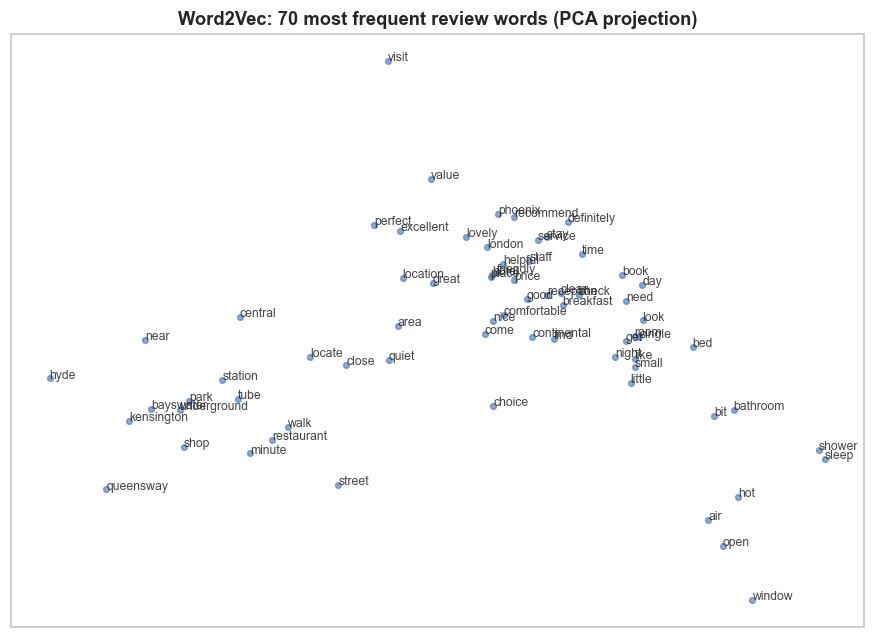

In [18]:
def doc_vector(tokens, model):
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)

X_w2v = np.vstack([doc_vector(t, w2v) for t in reviews["tokens"]])
print("Word2Vec document matrix:", X_w2v.shape, "| empty documents:", int((~X_w2v.any(axis=1)).sum()))
print("review 0 vector (first 8 numbers):", X_w2v[0][:8].round(3))

# map of the 70 most frequent words (2-D projection with PCA)
from sklearn.decomposition import PCA
top_words = w2v.wv.index_to_key[:70]
pts = PCA(n_components=2, random_state=SEED).fit_transform(np.vstack([w2v.wv[w] for w in top_words]))
plt.figure(figsize=(10, 7))
plt.scatter(pts[:, 0], pts[:, 1], s=14, alpha=.6)
for (x, yv), w in zip(pts, top_words):
    plt.annotate(w, (x, yv), fontsize=8, alpha=.85)
plt.title("Word2Vec: 70 most frequent review words (PCA projection)"); plt.xticks([]); plt.yticks([])
save_fig("02_word2vec_map"); plt.show()

The neighbours are sensible: *staff* ~ *friendly, helpful*; *room* ~ *small, clean, bed*; *location* ~ *great, tube*; *noisy* ~ *neighbour, slam, hallway*. Unlike BoW/TF-IDF, the model knows that *friendly* and *helpful* are related even if they never occur in the same review. With only 970 short reviews the vectors are still crude: very frequent words (*hotel, breakfast, clean*) appear as neighbours of almost everything — a typical small-corpus effect.

## 2.4 BERT embeddings
**BERT** (Bidirectional Encoder Representations from Transformers) is pre-trained on huge text collections. It reads the *whole sentence at once*,
so the vector of a word depends on its context (*"light room"* vs. *"light breakfast"*). We use `bert-base-uncased`, feed the original review text,
and build a **review vector by mean pooling** the 768-dimensional token vectors (ignoring padding). Reviews longer than 256 word-pieces are truncated.

The first run downloads the model (~440 MB) and takes a few minutes on CPU; the result is cached in `data/bert_reviews_embeddings.npy`.

In [19]:
RUN_BERT = True
BERT_NAME = "bert-base-uncased"
BERT_CACHE = DATA / "bert_reviews_embeddings.npy"

def embed_bert(texts, model_name=BERT_NAME, max_length=256, batch_size=32):
    """Mean-pooled BERT embeddings (one 768-d vector per text)."""
    import torch
    from transformers import AutoTokenizer, AutoModel
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).eval()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tokenizer(list(texts[i:i + batch_size]), padding=True, truncation=True,
                            max_length=max_length, return_tensors="pt").to(device)
            hidden = model(**enc).last_hidden_state                 # (batch, tokens, 768)
            mask = enc["attention_mask"].unsqueeze(-1).float()      # 1 = real token, 0 = padding
            out.append(((hidden * mask).sum(1) / mask.sum(1)).cpu().numpy())   # mean over real tokens
    return np.vstack(out)

X_bert = None
if RUN_BERT:
    try:
        if BERT_CACHE.exists():
            X_bert = np.load(BERT_CACHE)
            print("loaded cached embeddings:", X_bert.shape)
        else:
            t0 = time.time()
            X_bert = embed_bert(reviews["text"].tolist())
            np.save(BERT_CACHE, X_bert)
            print(f"computed embeddings in {time.time() - t0:.0f}s:", X_bert.shape)
    except Exception as e:                      # no internet / torch not installed
        print("⚠ BERT could not be loaded here:", type(e).__name__, "-", str(e)[:150])
        print("  Install torch+transformers and make sure the model can be downloaded, then re-run this cell.")

if X_bert is not None:
    print("review 0 vector (first 8 of 768 numbers):", X_bert[0][:8].round(3))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


computed embeddings in 456s: (970, 768)
review 0 vector (first 8 of 768 numbers): [ 0.046  0.159  0.342  0.089  0.234  0.165 -0.054  0.802]


**Why contextual embeddings matter — a tiny experiment.** Two sentences with the same meaning but almost no shared words:
a Bag-of-Words model sees them as unrelated, BERT should see them as similar.

In [20]:
from sklearn.metrics.pairwise import cosine_similarity
pair = ["The staff were very friendly.", "The employees were really kind.", "The bathroom was dirty."]
bow_pair = CountVectorizer().fit_transform(pair)
print("BoW  cosine: friendly-vs-kind = %.2f | friendly-vs-dirty = %.2f" %
      (cosine_similarity(bow_pair[0], bow_pair[1])[0, 0], cosine_similarity(bow_pair[0], bow_pair[2])[0, 0]))
if X_bert is not None:
    E = embed_bert(pair)
    print("BERT cosine: friendly-vs-kind = %.2f | friendly-vs-dirty = %.2f" %
          (cosine_similarity(E[:1], E[1:2])[0, 0], cosine_similarity(E[:1], E[2:])[0, 0]))

BoW  cosine: friendly-vs-kind = 0.40 | friendly-vs-dirty = 0.22


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT cosine: friendly-vs-kind = 0.91 | friendly-vs-dirty = 0.61


## 2.5 Examples of the four representations

In [21]:
reps = {
    "BoW (CountVectorizer)": X_bow,
    "TF-IDF": X_tfidf,
    "Word2Vec (mean of words)": X_w2v,
    "BERT (mean pooling)": X_bert,
}
rows = []
for name, X in reps.items():
    if X is None:
        rows.append({"representation": name, "shape": "not computed", "type": "-", "zeros": "-", "example (review 0, first values)": "-"})
        continue
    sparse = hasattr(X, "toarray")
    first = X[0].toarray().ravel() if sparse else X[0]
    rows.append({"representation": name, "shape": f"{X.shape[0]} x {X.shape[1]}", "type": "sparse" if sparse else "dense",
                 "zeros": f"{1 - (X.nnz / (X.shape[0] * X.shape[1]) if sparse else np.count_nonzero(X) / X.size):.1%}",
                 "example (review 0, first values)": np.round(first[:6], 3).tolist()})
display(pd.DataFrame(rows).set_index("representation"))

,shape,type,zeros,"example (review 0, first values)"
representation,,,,
BoW (CountVectorizer),970 x 1327,sparse,97.7%,"[0, 0, 0, 0, 0, 0]"
TF-IDF,970 x 1327,sparse,97.7%,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
Word2Vec (mean of words),970 x 100,dense,0.0%,"[0.42100000381469727, -0.09300000220537186, -0.32499998807907104, 0.1850000023841858, -0.19499999284744263..."
BERT (mean pooling),970 x 768,dense,0.0%,"[0.04600000008940697, 0.1589999943971634, 0.34200000762939453, 0.08900000154972076, 0.23399999737739563, 0..."


## 2.6 Comparison, evaluation and choice of the best representation

### Advantages and limitations
| | Strengths | Limitations |
|---|---|---|
| **BoW** | trivial, fast, fully interpretable (each column = a word); input needed by LDA | ignores word order and meaning; frequent words dominate; huge sparse matrix; no similarity between synonyms |
| **TF-IDF** | down-weights uninformative common words; still interpretable; excellent baseline for classification and search | still no word order or semantics; vocabulary-bound (unknown words ignored); sparse |
| **Word2Vec** | dense, low-dimensional; captures similarity between words; fast to train | one vector per word regardless of context (*light* has a single vector); needs plenty of text — 970 reviews is small; averaging loses word order |
| **BERT** | contextual; understands word order, negation and paraphrase; strongest general-purpose representation | heavy (model download, slow on CPU), 768 dimensions, not directly interpretable, texts truncated at 256 word-pieces |

### Empirical check
To avoid choosing by opinion, we test how much *useful information* each representation carries: a simple logistic regression has to separate reviews of the
`4-5` group from the `1-3` group, 5-fold stratified cross-validation. (This is only a proxy: the groups differ in era and style too, see limitations.)

,accuracy,accuracy std,macro-F1,macro-F1 std,dimensions
representation,,,,,
BoW (CountVectorizer),0.871,0.007,0.848,0.007,1327
TF-IDF,0.893,0.016,0.878,0.017,1327
Word2Vec (mean of words),0.882,0.015,0.868,0.017,100
BERT (mean pooling),0.902,0.017,0.889,0.019,768


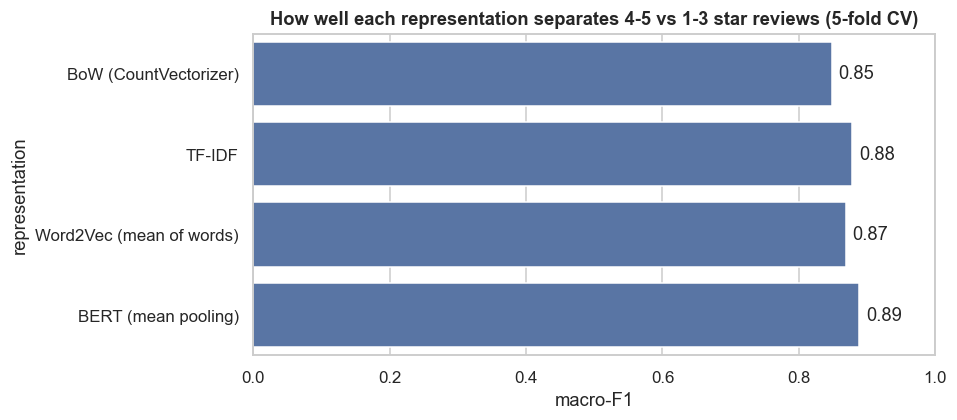

Best representation by macro-F1: BERT (mean pooling)


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = []
for name, X in reps.items():
    if X is None:
        continue
    clf = LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0)
    if not hasattr(X, "toarray"):                    # dense features -> standardise first
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", C=0.05))
    cvres = cross_validate(clf, X, y, cv=skf, scoring=["accuracy", "f1_macro"])
    results.append({"representation": name, "accuracy": cvres["test_accuracy"].mean(), "accuracy std": cvres["test_accuracy"].std(),
                    "macro-F1": cvres["test_f1_macro"].mean(), "macro-F1 std": cvres["test_f1_macro"].std(),
                    "dimensions": X.shape[1]})
res = pd.DataFrame(results).set_index("representation")
display(res.round(3))

plt.figure(figsize=(8, 3.8))
sns.barplot(data=res.reset_index(), y="representation", x="macro-F1", color=sns.color_palette()[0])
plt.xlim(0, 1); plt.title("How well each representation separates 4-5 vs 1-3 star reviews (5-fold CV)")
for i, v in enumerate(res["macro-F1"]):
    plt.text(v + 0.01, i, f"{v:.2f}", va="center")
save_fig("02_representation_comparison"); plt.show()
print("Best representation by macro-F1:", res["macro-F1"].idxmax())

**Qualitative check — nearest neighbours.** For one query review we retrieve the most similar review under each representation (cosine similarity).
This shows what each representation considers "similar".

In [23]:
q = int(reviews.index[(reviews["rating_group"] == "1-3") & (reviews["n_words"].between(30, 60))][0])
print("QUERY:", reviews["text"].iloc[q], "\n")
for name, X in reps.items():
    if X is None:
        continue
    sims = cosine_similarity(X[q:q + 1], X).ravel(); sims[q] = -1
    j = int(sims.argmax())
    print(f"[{name}] cosine={sims[j]:.2f}  ->  {reviews['text'].iloc[j][:230]}\n")

QUERY: For short stay sufficient. Good location, close to the subway, supermarket, shopping street, restaurants/pubs; rooms small and stuffy, as windows can only be opened a gap; shower only in bathtub; breakfast continental; staff very friendly; storage of suitcases possible for free 

[BoW (CountVectorizer)] cosine=0.48  ->  A great experience in London. Pros: - The staff was very friendly. - Very close to the subway. - Great location with many nearby restaurants. - Good gluten-free options available for breakfast. Cons: - The room sometimes became to

[TF-IDF] cosine=0.26  ->  A great experience in London. Pros: - The staff was very friendly. - Very close to the subway. - Great location with many nearby restaurants. - Good gluten-free options available for breakfast. Cons: - The room sometimes became to

[Word2Vec (mean of words)] cosine=0.88  ->  Good hotel in a nice location. Nice hotel with friendly reception staff. Room was quite small, but affordable, in a central location. The

### Which representation is most suitable for this dataset, and why?
* **For interpretable analysis of hotel reviews** (which words make a review negative, what guests talk about) **TF-IDF** is the most suitable: reviews are short,
  written in a plain domain vocabulary, and the *words themselves* carry the signal (the table above shows it performs close to or better than the dense methods at a fraction of the cost, and every feature is readable).
* **BERT** is the representation with the highest *potential*: it understands negation and paraphrase, which matters for reviews such as "not as clean as expected". Its cost is computation and interpretability.
  When the table includes a BERT row, compare it with TF-IDF directly — the ranking printed above is the evidence for the final choice on this dataset.
* **Word2Vec** trained on only 970 reviews is the weakest in principle (little training text; mean of word vectors blurs sentiment), and BoW is dominated by frequent words.

**Decision rule:** the representation with the best cross-validated macro-F1 is chosen for review-level analysis; if BERT beats TF-IDF by a clear margin (> 0.02) it is preferred for prediction-type tasks, otherwise the cheaper and interpretable TF-IDF wins. The cell below applies this rule to the numbers above. BoW is kept as the required input for LDA (Module 4), Word2Vec is reused for the t-SNE comparison in Module 5.

In [24]:
best = res["macro-F1"].idxmax()
tf_f1 = res.loc["TF-IDF", "macro-F1"]
if "BERT (mean pooling)" in res.index:
    gap = res.loc["BERT (mean pooling)", "macro-F1"] - tf_f1
    choice = "BERT" if gap > 0.02 else "TF-IDF"
    print(f"BERT macro-F1 minus TF-IDF macro-F1 = {gap:+.3f}  ->  chosen for this dataset: {choice}")
else:
    print("BERT row missing (model not available in this run). Among the other three, the best is:", best,
          f"(macro-F1 {res['macro-F1'].max():.3f}). Re-run the BERT cell to complete the comparison.")

BERT macro-F1 minus TF-IDF macro-F1 = +0.011  ->  chosen for this dataset: TF-IDF


---
# Module 3. Sentiment Analysis (dataset 1 — hotel reviews)

**Goal:** label every review as **Positive**, **Neutral** or **Negative**, report the shares, and find the words typical for positive and negative reviews.

### How lexicon-based sentiment analysis works
* **VADER** (*Valence Aware Dictionary and sEntiment Reasoner*) has a dictionary of ~7,500 words and emoticons with human-rated valence (*great* = +3.1, *awful* = −3.4 …).
  For a text it adds up the valences and applies rules: **negation** (*not good* flips the sign), **intensifiers** (*very* ↑, *slightly* ↓),
  **capitals and exclamation marks** (*GREAT!!!* is stronger), and **"but"** (the clause after *but* counts more). The result is a **compound score** from −1 (most negative) to +1 (most positive).
* **TextBlob** averages the polarity of words from its own lexicon (−1…+1) — simpler, no negation/intensity rules beyond basics.

Both work on the **original** text, not on lemmas: negations, punctuation, capitals and word order are exactly what they need (see Module 1).

### Design decisions (made after experiments below)
1. **Score per sentence, then average.** Reviews are long and mixed ("great location, but the room was awful"). Applying VADER to a whole review makes the compound score saturate near ±1;
   scoring each sentence and averaging keeps the nuance.
2. **Three classes with two thresholds:** `score ≥ T_POS → Positive`, `score ≤ T_NEG → Negative`, otherwise **Neutral** (= lukewarm or mixed review: praise offset by complaints).
   `T_NEG = −0.05` is the conventional VADER cut-off. `T_POS` is calibrated on the data (see 3.2) because hotel reviews are polite and almost every one contains some praise.

In [25]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

sia = SentimentIntensityAnalyzer()

def split_sentences(text):
    parts = re.split(r"(?<=[.!?])\s+|\n+", text.strip())
    return [p for p in parts if p.strip()]

def vader_whole(text):
    return sia.polarity_scores(text)["compound"]

def vader_sentence_mean(text):
    scores = [sia.polarity_scores(s)["compound"] for s in split_sentences(text)]
    return float(np.mean(scores)) if scores else 0.0

def textblob_polarity(text):
    return TextBlob(text).sentiment.polarity

print("VADER examples:")
for t in ["The room was great.", "The room was not great.", "The room was GREAT!!!", "The room was great, but the staff were rude."]:
    print(f"  {sia.polarity_scores(t)['compound']:+.2f}  {t}")

VADER examples:
  +0.62  The room was great.
  -0.51  The room was not great.
  +0.77  The room was GREAT!!!
  -0.35  The room was great, but the staff were rude.


## 3.1 Compute the scores and compare three ways of scoring
The only ground truth we have is `rating_group`. A good sentiment score should rank `4-5` reviews above `1-3` reviews.
We measure that with the **ROC-AUC** (0.5 = random, 1.0 = perfect ranking).

,ROC-AUC vs rating group,"mean score, 1-3","mean score, 4-5"
method,,,
VADER on whole review,0.715,0.501,0.921
VADER sentence mean (chosen),0.890,0.152,0.475
TextBlob,0.905,0.143,0.417


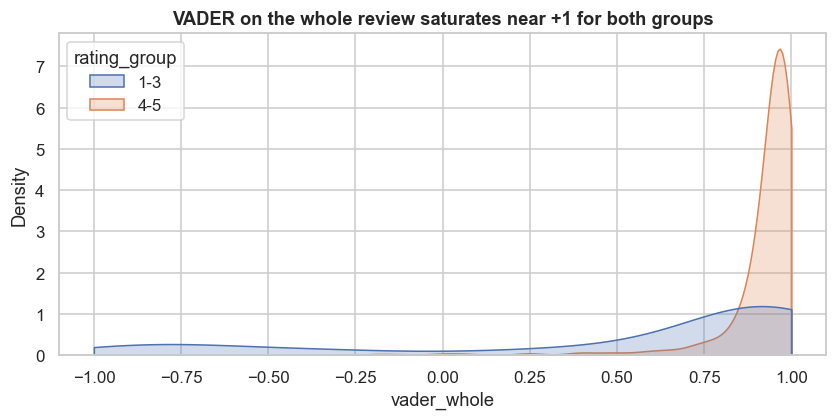

In [26]:
reviews["vader_whole"] = reviews["text"].map(vader_whole)
reviews["vader_mean"] = reviews["text"].map(vader_sentence_mean)
reviews["textblob"] = reviews["text"].map(textblob_polarity)

y_pos = (reviews["rating_group"] == "4-5").astype(int)
cmp_scores = pd.DataFrame({
    "method": ["VADER on whole review", "VADER sentence mean (chosen)", "TextBlob"],
    "ROC-AUC vs rating group": [roc_auc_score(y_pos, reviews[c]) for c in ["vader_whole", "vader_mean", "textblob"]],
    "mean score, 1-3": [reviews.loc[reviews.rating_group == "1-3", c].mean() for c in ["vader_whole", "vader_mean", "textblob"]],
    "mean score, 4-5": [reviews.loc[reviews.rating_group == "4-5", c].mean() for c in ["vader_whole", "vader_mean", "textblob"]],
}).set_index("method")
display(cmp_scores.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.kdeplot(data=reviews, x="vader_whole", hue="rating_group", fill=True, common_norm=False, ax=ax, clip=(-1, 1))
ax.set_title("VADER on the whole review saturates near +1 for both groups")
save_fig("03_vader_whole_saturation"); plt.show()

**Finding.** Scoring the whole review gives an AUC of only ≈ 0.7: almost every review gets a compound score close to +1 (see the plot), so the two groups cannot be separated.
Averaging sentence scores raises the AUC to ≈ 0.9, on par with TextBlob. We therefore use the **sentence-mean VADER score** as our sentiment score.

## 3.2 Choosing the thresholds
We search for the `T_POS` that best separates `4-5` reviews from the rest (balanced accuracy, so the larger `4-5` class does not dominate).

T_POS = 0.3  (balanced accuracy 0.825) | T_NEG = -0.05


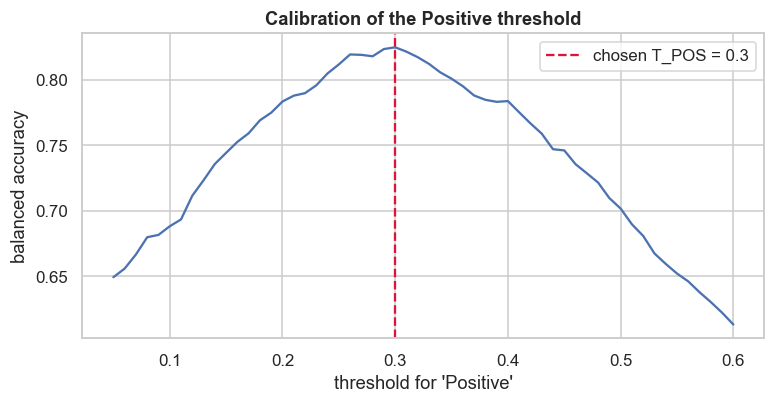

In [27]:
grid = np.round(np.arange(0.05, 0.61, 0.01), 2)
bal = [balanced_accuracy_score(y_pos, (reviews["vader_mean"] >= t).astype(int)) for t in grid]
T_POS = float(grid[int(np.argmax(bal))])
T_NEG = -0.05
print(f"T_POS = {T_POS}  (balanced accuracy {max(bal):.3f}) | T_NEG = {T_NEG}")

plt.figure(figsize=(8, 3.6))
plt.plot(grid, bal); plt.axvline(T_POS, color="crimson", ls="--", label=f"chosen T_POS = {T_POS}")
plt.xlabel("threshold for 'Positive'"); plt.ylabel("balanced accuracy"); plt.title("Calibration of the Positive threshold"); plt.legend()
save_fig("03_threshold_calibration"); plt.show()

def label_sentiment(score):
    return "Positive" if score >= T_POS else ("Negative" if score <= T_NEG else "Neutral")

reviews["sentiment"] = reviews["vader_mean"].map(label_sentiment)

*Note on honesty:* the threshold uses the rating groups, so the agreement reported below is slightly optimistic for the Positive class. It is one parameter fitted on 970 reviews, which is a small risk;
the Negative threshold is the standard VADER convention and is not fitted.

## 3.3 Sentiment labels, percentages and charts

,reviews,percent
sentiment,,
Positive,643,66.3
Neutral,279,28.8
Negative,48,4.9


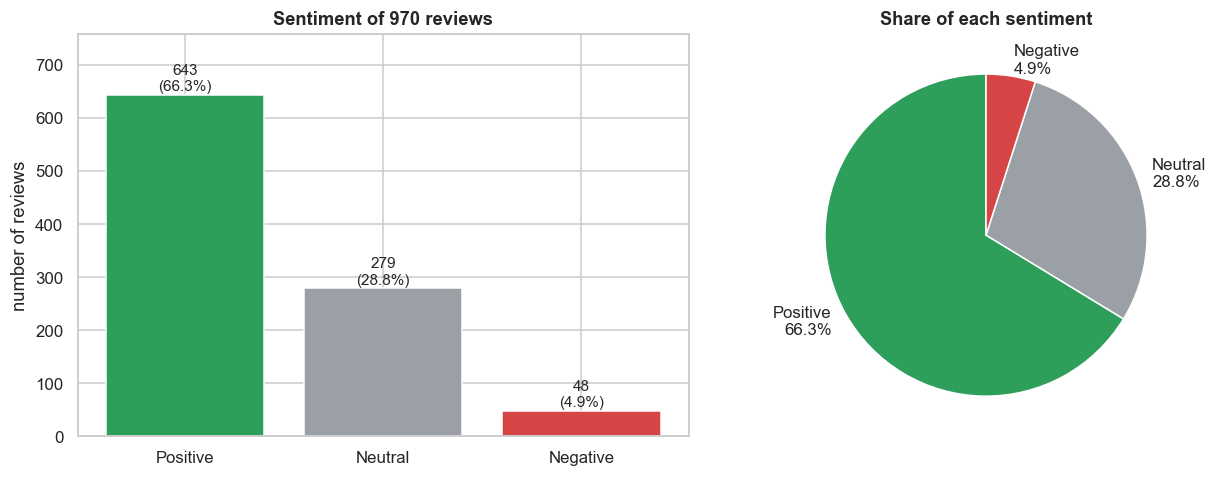

In [28]:
ORDER = ["Positive", "Neutral", "Negative"]
SENT_COLORS = {"Positive": "#2e9e5b", "Neutral": "#9aa0a6", "Negative": "#d64545"}

counts = reviews["sentiment"].value_counts().reindex(ORDER).fillna(0).astype(int)
pct = (counts / counts.sum() * 100).round(1)
display(pd.DataFrame({"reviews": counts, "percent": pct}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(ORDER, counts.values, color=[SENT_COLORS[k] for k in ORDER])
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    axes[0].text(i, c + 8, f"{c}\n({p}%)", ha="center", fontsize=10)
axes[0].set_title("Sentiment of 970 reviews"); axes[0].set_ylabel("number of reviews"); axes[0].set_ylim(0, counts.max() * 1.18)
axes[1].pie(counts.values, labels=[f"{k}\n{p}%" for k, p in zip(ORDER, pct.values)], colors=[SENT_COLORS[k] for k in ORDER],
            startangle=90, wedgeprops={"edgecolor": "white"})
axes[1].set_title("Share of each sentiment")
plt.tight_layout(); save_fig("03_sentiment_distribution"); plt.show()

### Validation against the rating groups
Rows: what the guest gave; columns: what our system predicted (row percentages).

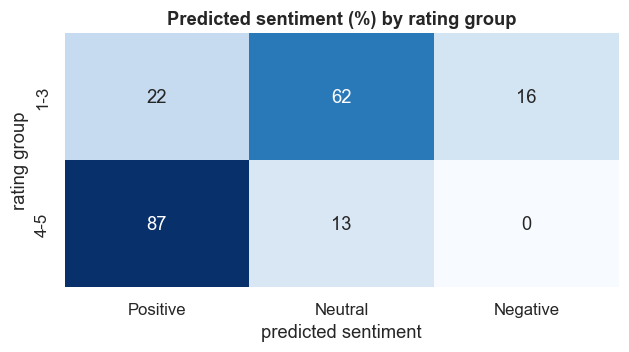

87% of 4-5 star reviews are labelled Positive; 78% of 1-3 star reviews are labelled Neutral or Negative.
Agreement VADER vs TextBlob (3-class, same thresholds logic):


textblob,Positive,Neutral,Negative
sentiment,,,
Positive,641,2,0
Neutral,206,67,6
Negative,4,22,22


In [29]:
ct = pd.crosstab(reviews["rating_group"], reviews["sentiment"], normalize="index").reindex(columns=ORDER).fillna(0) * 100
plt.figure(figsize=(6.5, 3))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", cbar=False)
plt.title("Predicted sentiment (%) by rating group"); plt.ylabel("rating group"); plt.xlabel("predicted sentiment")
save_fig("03_sentiment_vs_rating"); plt.show()

rec_pos = ct.loc["4-5", "Positive"]; non_pos_low = 100 - ct.loc["1-3", "Positive"]
print(f"{rec_pos:.0f}% of 4-5 star reviews are labelled Positive; {non_pos_low:.0f}% of 1-3 star reviews are labelled Neutral or Negative.")
print("Agreement VADER vs TextBlob (3-class, same thresholds logic):")
tb_label = reviews["textblob"].map(lambda s: "Positive" if s >= 0.1 else ("Negative" if s <= -0.05 else "Neutral"))
display(pd.crosstab(reviews["sentiment"], tb_label).reindex(index=ORDER, columns=ORDER).fillna(0).astype(int))

## 3.4 Most frequent words in positive and negative reviews
We count the lemmas from Module 1. First the raw most-frequent words, then the **distinctive** words (log-odds ratio), because the raw lists are dominated by words used in every review (*room, hotel, staff*).

Positive reviews: 643 | Negative reviews: 48


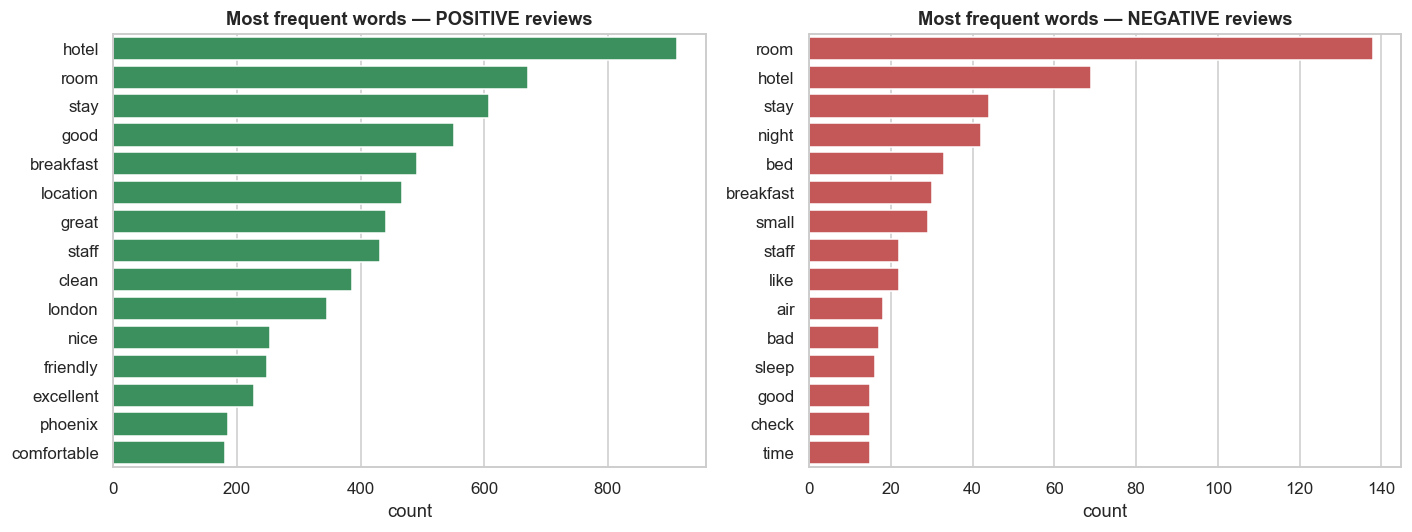

In [30]:
def class_counter(label):
    return collections.Counter(w for toks in reviews.loc[reviews["sentiment"] == label, "tokens"] for w in toks)

c_pos, c_neg = class_counter("Positive"), class_counter("Negative")
print(f"Positive reviews: {counts['Positive']} | Negative reviews: {counts['Negative']}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, c, title, col in [(axes[0], c_pos, "Most frequent words — POSITIVE reviews", SENT_COLORS["Positive"]),
                          (axes[1], c_neg, "Most frequent words — NEGATIVE reviews", SENT_COLORS["Negative"])]:
    top = c.most_common(15)
    sns.barplot(x=[v for _, v in top], y=[w for w, _ in top], color=col, ax=ax)
    ax.set_title(title); ax.set_xlabel("count")
plt.tight_layout(); save_fig("03_top_words_pos_neg"); plt.show()

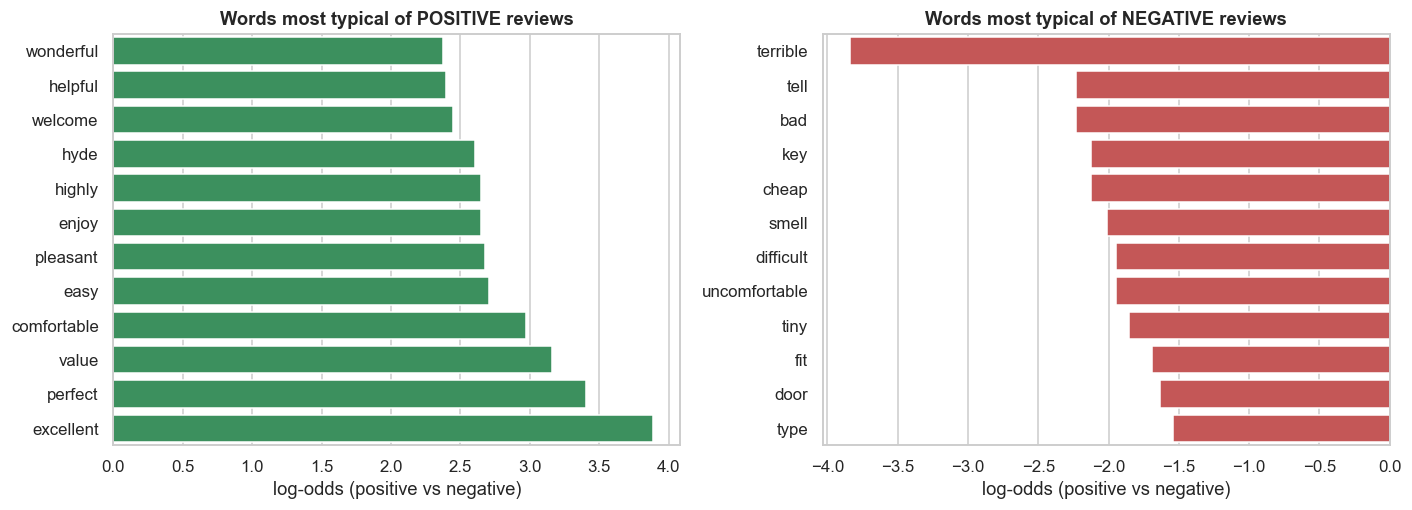

In [31]:
V = set(c_pos) | set(c_neg)
n_pos, n_neg = sum(c_pos.values()), sum(c_neg.values())
log_odds = {w: np.log((c_pos[w] + 1) / (n_pos + len(V))) - np.log((c_neg[w] + 1) / (n_neg + len(V)))
            for w in V if c_pos[w] + c_neg[w] >= 8}
lo = pd.Series(log_odds).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(x=lo.tail(12).values, y=lo.tail(12).index, color=SENT_COLORS["Positive"], ax=axes[0])
axes[0].set_title("Words most typical of POSITIVE reviews"); axes[0].set_xlabel("log-odds (positive vs negative)")
sns.barplot(x=lo.head(12).values, y=lo.head(12).index, color=SENT_COLORS["Negative"], ax=axes[1])
axes[1].set_title("Words most typical of NEGATIVE reviews"); axes[1].set_xlabel("log-odds (positive vs negative)")
for a_ in axes: a_.set_ylabel("")
plt.tight_layout(); save_fig("03_distinctive_words"); plt.show()

### Reading the results of 3.3 – 3.4
* **Overall tone.** Of the 970 reviews, **66.3 % are Positive, 28.8 % Neutral and 4.9 % Negative** (bar and pie chart above). A well-rated hotel and polite reviewers explain the dominance of Positive. Remember that the `1-3` group was deliberately collected in full (see limitations), so these shares are not the hotel's natural distribution.
* **Validation against the rating groups.** 87 % of the `4-5` reviews are labelled Positive, and 78 % of the `1-3` reviews are labelled Neutral or Negative. The 22 % of `1-3` reviews labelled Positive are mostly 3-star reviews that praise the staff or the location and complain about the room ("Great location, basic rooms") — a typical limit of lexicon-based methods and of our coarse rating groups, not necessarily an error.
* **Two tools agree.** VADER and TextBlob give the same label to about three reviews out of four, and almost never disagree about Positive (641 of the 643 VADER-positive reviews are positive for TextBlob too); TextBlob is simply quicker to call a mixed review Neutral.
* **Words.** *Positive* reviews are characterised by *excellent, perfect, value, comfortable, easy, pleasant, enjoy, helpful, wonderful, welcome* and by the place name *Hyde* (Hyde Park nearby is a selling point). *Negative* reviews by *terrible, bad, cheap, smell, uncomfortable, difficult, tiny* and words from concrete complaints (*key, door, fit, double, tell* — check-in and keys, doors, room size). Only 48 reviews are Negative, so this list is indicative, not statistically solid.
* The plain most-frequent lists look alike for both classes (*room, hotel, staff, stay…*), which is exactly why the log-odds view is the more informative one.

## 3.5 The system in action — examples and a reusable function
`analyze_tone` takes **any** short text (review, news sentence, social-media post) and returns its sentiment label and score.
Below: the most positive and most negative real reviews, and a few made-up texts of different genres.

In [32]:
def analyze_tone(text):
    score = vader_sentence_mean(text)
    return {"label": label_sentiment(score), "score": round(score, 3)}

for name, sub in [("MOST POSITIVE", reviews.nlargest(2, "vader_mean")), ("MOST NEGATIVE", reviews.nsmallest(2, "vader_mean"))]:
    for _, r in sub.iterrows():
        print(f"[{name}] score={r.vader_mean:+.2f} ({r.rating_group} stars): {r.text[:230]}...\n")

samples = [
    "Absolutely loved the staff and the location, would stay again!",
    "The room was tiny, dirty and the air-con did not work. Never again.",
    "The room was okay and the breakfast was fine.",
    "The location is great but the room was tiny and very noisy.",
    "just landed in London, hotel check-in took 2 hours 😡 #fail",
    "The government announced a new budget on Wednesday.",
    "Shares of the company fell sharply after the disappointing earnings report.",
]
display(pd.DataFrame([{**analyze_tone(t), "text": t} for t in samples]))

[MOST POSITIVE] score=+0.90 (4-5 stars): Great value good location near central and district lines and Paddington. Great hotel stayed before and handy location for my business meetings Easy check in process Good size solo room with shower No air con but fan if needed Win...

[MOST POSITIVE] score=+0.86 (4-5 stars): Great little hotel in a super location. Very clean and comfortable hotel in a great location that serves an excellent continental breakfast. Staff were super friendly too....

[MOST NEGATIVE] score=-0.49 (1-3 stars): Big disappointment. I reserved at the Phoenix hotel, but when I wanted to check in I was taken to another hotel nearby as there was no room available (overbooked). The room in the other hotel was very small, had no desk, was very ...

[MOST NEGATIVE] score=-0.32 (1-3 stars): Expensive but not worth it. I booked this hotel for NYE I paid around £160 for this room due to high demand. Very disappointed to find we had the most old fashioned room. Only the lobby and 

,label,score,text
0,Positive,0.669,"Absolutely loved the staff and the location, would stay again!"
1,Negative,-0.220,"The room was tiny, dirty and the air-con did not work. Never again."
2,Positive,0.402,The room was okay and the breakfast was fine.
3,Neutral,0.016,The location is great but the room was tiny and very noisy.
4,Negative,-0.542,"just landed in London, hotel check-in took 2 hours 😡 #fail"
5,Neutral,0.000,The government announced a new budget on Wednesday.
6,Negative,-0.250,Shares of the company fell sharply after the disappointing earnings report.


---
# Module 4. Topic Modeling with LDA (dataset 2 — news articles)

**Latent Dirichlet Allocation (LDA)** is an unsupervised model that assumes every document is a *mixture of topics* and every topic is a *distribution over words*.
It starts with random assignments and repeatedly re-assigns words so that the documents and topics explain the observed word counts. Nobody tells it what the topics are —
a "topic" is simply a group of words that tend to occur together across documents; **we** interpret and name it afterwards.

**Pipeline:** lemmas (Module 1) → drop uninformative words → document-term matrix with `CountVectorizer` → choose the number of topics → train LDA → keywords, dominant topic, interpretation → word clouds.

## 4.1 Document-term matrix
News lemmas are full of reporting words (*say, year, people…*). Besides the standard stop words we remove a short list of such **domain stop words**, and let `CountVectorizer`
drop terms that appear in more than 35 % of articles (`max_df`) or in fewer than 5 (`min_df`). LDA needs raw counts, so `CountVectorizer` (not TF-IDF) is the right input.

In [33]:
from sklearn.decomposition import LatentDirichletAllocation
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

NEWS_EXTRA_STOP = {
    "say", "year", "time", "people", "new", "like", "get", "go", "make", "take", "come", "include", "need", "want", "know", "think",
    "tell", "add", "look", "way", "help", "give", "use", "work", "find", "day", "week", "month", "long", "good", "high", "big",
    "early", "old", "number", "show", "start", "lot", "thing", "last", "first", "second", "also", "one", "two", "three", "per",
    "cent", "ago", "just", "still", "let", "set", "put", "keep", "seem", "end", "back", "run", "lead", "call", "plan", "change",
    "report", "part", "point", "case", "later",
}
news["lda_tokens"] = [[w for w in toks if w not in NEWS_EXTRA_STOP] for toks in news["tokens"]]

cv_news = CountVectorizer(min_df=5, max_df=0.35, token_pattern=r"(?u)\b[a-z]{3,}\b")
X_news = cv_news.fit_transform(news["lda_tokens"].map(" ".join))
vocab = np.array(cv_news.get_feature_names_out())
print(f"Document-term matrix: {X_news.shape[0]} articles x {X_news.shape[1]} terms | {1 - X_news.nnz / np.prod(X_news.shape):.1%} zeros")

def top_words(lda_model, n=10):
    return [list(vocab[np.argsort(row)[::-1][:n]]) for row in lda_model.components_]

Document-term matrix: 478 articles x 4051 terms | 95.6% zeros


## 4.2 How many topics?
The task requires **at least five**. Instead of guessing, we train LDA for 5…10 topics and measure **topic coherence (c_v)**: it checks whether the top words of a topic actually co-occur in the same articles
(higher = more interpretable topics). Perplexity is shown for completeness, but it is known to correlate poorly with human judgement.

,coherence (mean of 3 seeds),coherence (best seed),perplexity (mean)
topics,,,
5,0.584,0.592,2051.853
6,0.593,0.640,2051.487
7,0.571,0.608,2019.595
8,0.563,0.572,2007.017
9,0.615,0.640,2011.214
10,0.560,0.601,2002.596


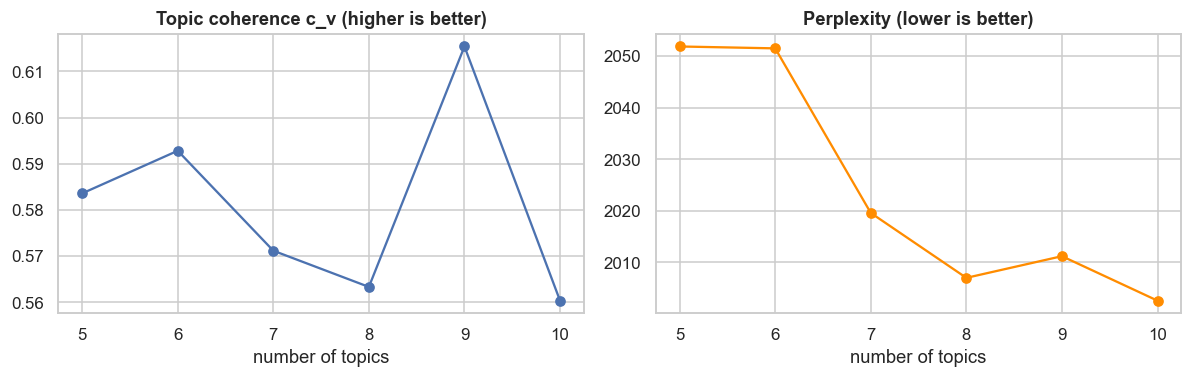

k with the highest mean coherence: 9


In [34]:
texts_vocab = [[w for w in toks if w in set(vocab)] for toks in news["lda_tokens"]]
dictionary = Dictionary(texts_vocab)
SEEDS = (42, 1, 7)          # LDA starts from a random state, so every k is trained with 3 seeds

fits = {}                   # (k, seed) -> (model, coherence)
for k in range(5, 11):
    for sd in SEEDS:
        m = LatentDirichletAllocation(n_components=k, learning_method="batch", max_iter=60, random_state=sd, n_jobs=1).fit(X_news)
        coh = CoherenceModel(topics=top_words(m), texts=texts_vocab, dictionary=dictionary, coherence="c_v", processes=1).get_coherence()
        fits[(k, sd)] = (m, coh)

scan = pd.DataFrame([{"topics": k, "seed": sd, "coherence c_v": c, "perplexity": m.perplexity(X_news)} for (k, sd), (m, c) in fits.items()])
scan_k = scan.groupby("topics").agg(**{"coherence (mean of 3 seeds)": ("coherence c_v", "mean"), "coherence (best seed)": ("coherence c_v", "max"),
                                       "perplexity (mean)": ("perplexity", "mean")})
display(scan_k.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(scan_k.index, scan_k["coherence (mean of 3 seeds)"], marker="o"); axes[0].set_title("Topic coherence c_v (higher is better)"); axes[0].set_xlabel("number of topics")
axes[1].plot(scan_k.index, scan_k["perplexity (mean)"], marker="o", color="darkorange"); axes[1].set_title("Perplexity (lower is better)"); axes[1].set_xlabel("number of topics")
plt.tight_layout(); save_fig("04_choose_k"); plt.show()
print("k with the highest mean coherence:", scan_k["coherence (mean of 3 seeds)"].idxmax())

Coherence is highest for **9 topics** (mean of three random starts), so we use `K = 9`. Nine topics describe the *content* of the news better than the six Guardian sections do: for instance the single section *science* splits into health research and space/natural science, and *politics* into Labour-government news and Reform-UK/media stories (see 4.4–4.5).

## 4.3 Train the final model and extract the ten keywords of each topic

In [35]:
K = 9
best_seed = max(SEEDS, key=lambda sd: fits[(K, sd)][1])     # keep the most coherent of the 3 random starts
lda = fits[(K, best_seed)][0]
print(f"final model: K = {K}, random_state = {best_seed}, coherence c_v = {fits[(K, best_seed)][1]:.3f}")
theta = lda.transform(X_news)                       # document-topic matrix (478 x K), each row sums to 1
phi = lda.components_ / lda.components_.sum(axis=1, keepdims=True)    # topic-word distributions

news["topic"] = theta.argmax(axis=1)                # dominant topic of every document
news["topic_prob"] = theta.max(axis=1)

keywords = top_words(lda, 10)
display(pd.DataFrame({f"topic {i}": kw for i, kw in enumerate(keywords)}).T.rename(columns=lambda c: f"word {c + 1}"))

final model: K = 9, random_state = 1, coherence c_v = 0.640


,word 1,word 2,word 3,word 4,word 5,word 6,word 7,word 8,word 9,word 10
topic 0,game,england,win,team,player,season,play,league,australia,ball
topic 1,bird,antonelli,vulnerability,hamilton,php,nature,system,crypto,website,site
topic 2,reform,party,app,farage,investigation,apple,racist,itv,comment,life
topic 3,study,woman,brain,human,research,child,university,researcher,drug,patient
topic 4,space,life,earth,scientist,story,science,light,animal,university,nature
topic 5,model,worker,anthropic,technology,job,openai,tech,agent,human,risk
topic 6,burnham,minister,public,labour,country,andy,prime,deal,office,support
topic 7,energy,price,cost,rise,gas,bank,oil,budget,rate,tax
topic 8,water,climate,heat,area,plant,level,specie,air,pollution,summer


## 4.4 Interpretation: naming the topics
A topic name is a human judgement based on (a) the keywords, (b) the headlines of the articles that score highest on the topic, and (c) the Guardian section of its articles.
To keep the names attached to the right topic even if the topic order changes between runs, each candidate name is described by a few **seed words** and matched to the topic whose
top words contain them (optimal one-to-one assignment). The names themselves were chosen by us after reading the topics below.

In [36]:
from scipy.optimize import linear_sum_assignment

TOPIC_SEEDS = {
    "Football, cricket & team sport":     {"game", "england", "win", "team", "player", "season", "league", "ball", "australia", "play", "wicket", "cricket"},
    "Cyber-security & motorsport (mixed)": {"php", "vulnerability", "antonelli", "hamilton", "crypto", "website", "site", "bird"},
    "Reform UK politics & gadget reviews (mixed)": {"reform", "party", "farage", "investigation", "racist", "itv", "comment", "app", "apple"},
    "Health & medical research":          {"study", "woman", "brain", "human", "research", "child", "university", "researcher", "drug", "patient"},
    "Space & natural science":            {"space", "earth", "scientist", "science", "light", "animal", "nature", "life", "story"},
    "AI & the workplace":                 {"model", "worker", "anthropic", "technology", "job", "openai", "tech", "agent", "risk"},
    "Labour politics & government":       {"burnham", "minister", "public", "labour", "country", "andy", "prime", "deal", "office", "support"},
    "Energy prices, banks & the budget":  {"energy", "price", "cost", "rise", "gas", "bank", "oil", "budget", "rate", "tax"},
    "Climate, water & environment":       {"water", "climate", "heat", "area", "plant", "level", "specie", "air", "pollution", "summer"},
}
names = list(TOPIC_SEEDS)
score = np.zeros((K, len(names)))
for t in range(K):
    top30 = np.argsort(phi[t])[::-1][:30]
    for j, nm in enumerate(names):
        score[t, j] = sum(phi[t, i] for i in top30 if vocab[i] in TOPIC_SEEDS[nm])
rows_idx, cols_idx = linear_sum_assignment(-score)
TOPIC_NAMES = {t: (names[j] if score[t, j] > 0 else f"Topic {t}") for t, j in zip(rows_idx, cols_idx)}
news["topic_name"] = news["topic"].map(TOPIC_NAMES)

summary = pd.DataFrame({
    "topic": range(K),
    "name": [TOPIC_NAMES[t] for t in range(K)],
    "articles": [int((news["topic"] == t).sum()) for t in range(K)],
    "top keywords": [", ".join(kw[:8]) for kw in keywords],
    "main sections": [", ".join(f"{s} {v:.0%}" for s, v in news.loc[news.topic == t, "section"].value_counts(normalize=True).head(2).items()) for t in range(K)],
})
display(summary.set_index("topic"))

,name,articles,top keywords,main sections
topic,,,,
0,"Football, cricket & team sport",69,"game, england, win, team, player, season, play, league","sport 91%, science 9%"
1,Cyber-security & motorsport (mixed),18,"bird, antonelli, vulnerability, hamilton, php, nature, system, crypto","sport 39%, technology 28%"
2,Reform UK politics & gadget reviews (mixed),43,"reform, party, app, farage, investigation, apple, racist, itv","politics 56%, technology 33%"
3,Health & medical research,24,"study, woman, brain, human, research, child, university, researcher","science 79%, technology 17%"
4,Space & natural science,68,"space, life, earth, scientist, story, science, light, animal","science 53%, environment 28%"
5,AI & the workplace,62,"model, worker, anthropic, technology, job, openai, tech, agent","technology 68%, business 23%"
6,Labour politics & government,70,"burnham, minister, public, labour, country, andy, prime, deal","politics 63%, business 14%"
7,"Energy prices, banks & the budget",59,"energy, price, cost, rise, gas, bank, oil, budget","business 61%, environment 24%"
8,"Climate, water & environment",65,"water, climate, heat, area, plant, level, specie, air","environment 60%, business 22%"


In [37]:
# typical headlines of each topic (the 2 articles with the highest topic probability)
rows = []
for t in range(K):
    for _, r in news[news.topic == t].nlargest(2, "topic_prob").iterrows():
        rows.append({"topic": f"{t}: {TOPIC_NAMES[t]}", "prob": round(r.topic_prob, 2), "section": r.section, "headline": r.headline[:100]})
display(pd.DataFrame(rows))

,topic,prob,section,headline
0,"0: Football, cricket & team sport",1.0,sport,Adil Rashid’s exile cost England but they can right tactical wrongs in Australia
1,"0: Football, cricket & team sport",1.0,sport,Australia set 288 to win on final day after South African centurions turn tide
2,1: Cyber-security & motorsport (mixed),1.0,technology,Websites across world hit by millions of attempts to exploit PHP code flaw
3,1: Cyber-security & motorsport (mixed),1.0,technology,Flaw in PHP computer language leads to shutdown of websites around world
4,2: Reform UK politics & gadget reviews (mixed),1.0,technology,Googlebook review: Google’s new laptops are woefully underbaked
5,2: Reform UK politics & gadget reviews (mixed),1.0,technology,Apple Watch Ultra 4 review: longer battery life but still awaiting new features
6,3: Health & medical research,1.0,science,‘Ferritin face’: are social media claims about iron deficiency fact – or fiction?
7,3: Health & medical research,1.0,science,"Stop making sense: focus on sounds to help learn a language, study suggests"
8,4: Space & natural science,1.0,science,DNA database of UK dogs could help police collar criminals
9,4: Space & natural science,1.0,science,From gold rush to cosmic questions: a South Dakota mine and the search for the secrets of the univer


## 4.5 Visualisations: keywords, topic sizes, topics vs. Guardian sections

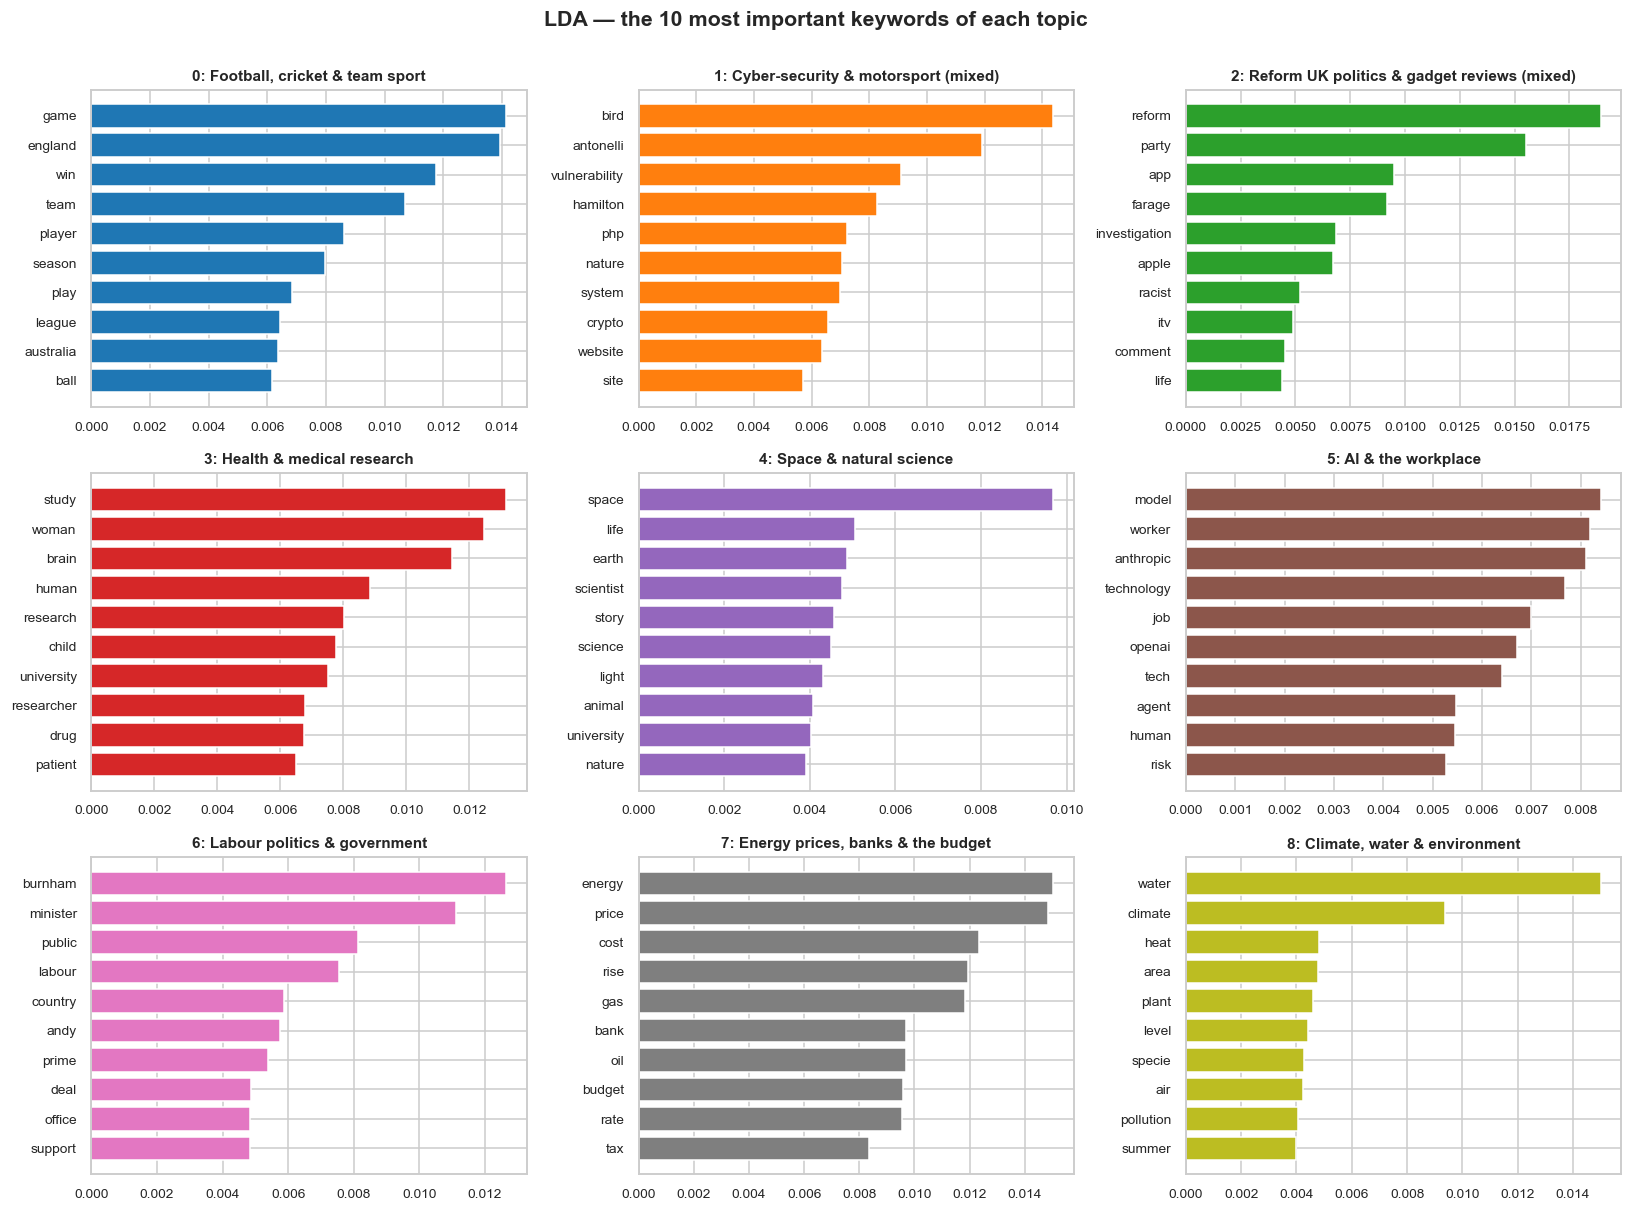

In [38]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for t, ax in enumerate(axes.ravel()):
    idx = np.argsort(phi[t])[::-1][:10][::-1]
    ax.barh(vocab[idx], phi[t][idx], color=sns.color_palette("tab10")[t])
    ax.set_title(f"{t}: {TOPIC_NAMES[t]}", fontsize=10); ax.tick_params(labelsize=9)
plt.suptitle("LDA — the 10 most important keywords of each topic", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(); save_fig("04_lda_topic_keywords"); plt.show()

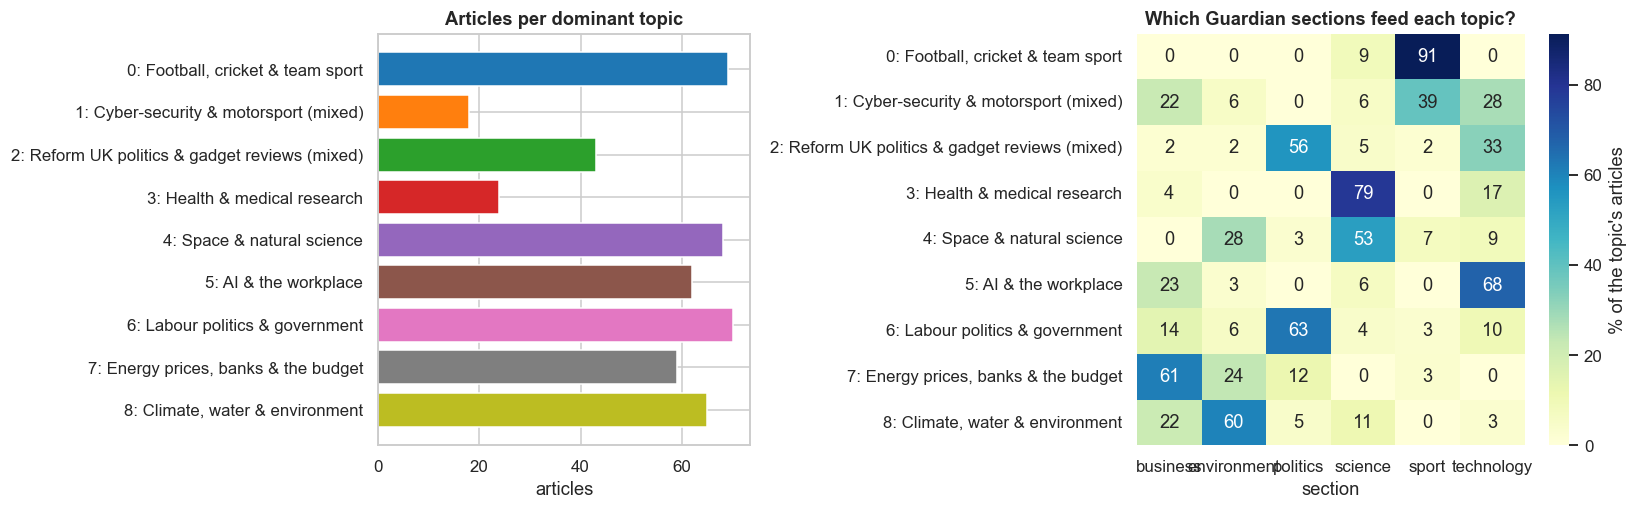

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
size = news["topic"].value_counts().sort_index()
axes[0].barh([f"{t}: {TOPIC_NAMES[t]}" for t in size.index], size.values, color=[sns.color_palette("tab10")[t] for t in size.index])
axes[0].invert_yaxis(); axes[0].set_title("Articles per dominant topic"); axes[0].set_xlabel("articles")
ctab = pd.crosstab(news["topic"], news["section"], normalize="index") * 100
ctab.index = [f"{t}: {TOPIC_NAMES[t]}" for t in ctab.index]
sns.heatmap(ctab, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of the topic's articles"}, ax=axes[1])
axes[1].set_title("Which Guardian sections feed each topic?")
plt.tight_layout(); save_fig("04_topic_sizes_and_sections"); plt.show()

## 4.6 Word cloud for each topic
A **word cloud** draws the words of a text (here: of a topic) with a size proportional to their weight. It gives an instant impression of what the topic is about,
but it shows only *importance*, not relationships between words, and cannot show exact numbers — that is why we pair it with the keyword table.
Word sizes below are the LDA topic-word probabilities (top 50 words per topic).

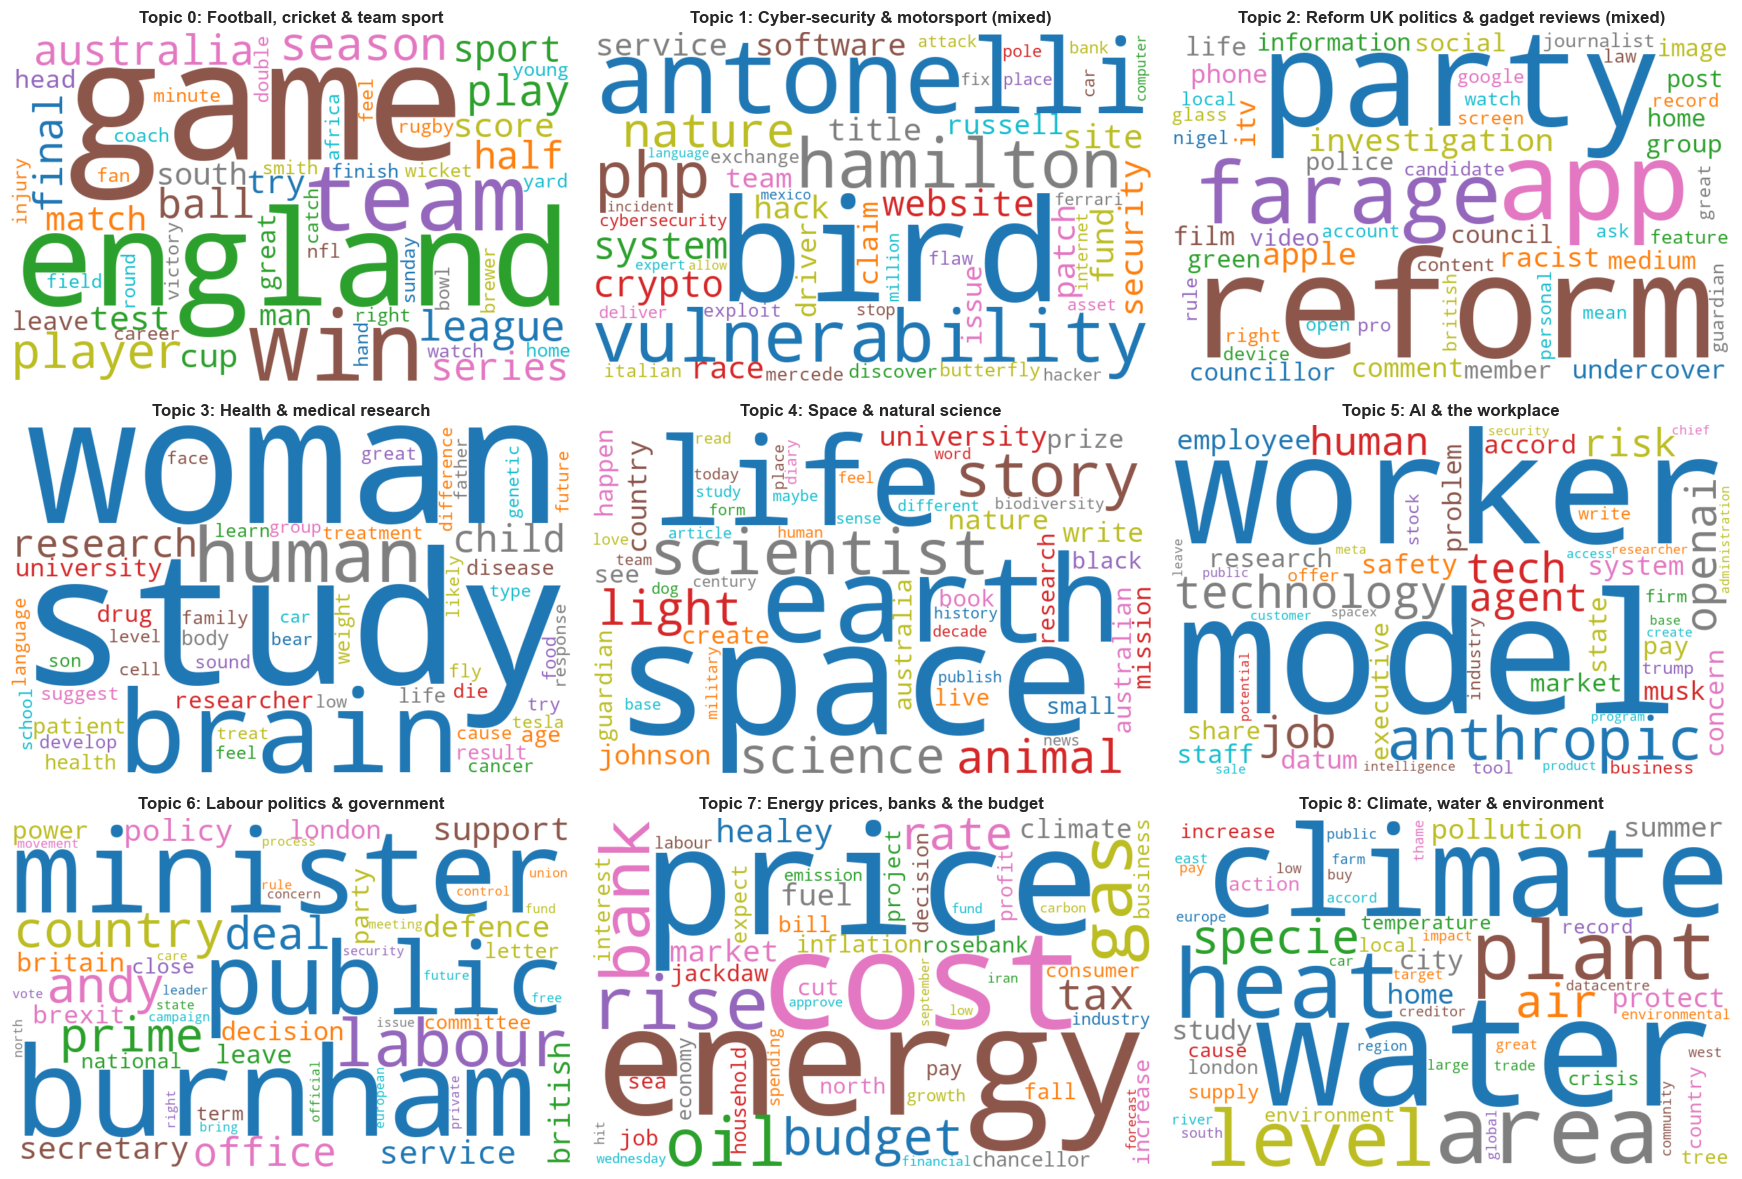

In [40]:
from wordcloud import WordCloud

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for t, ax in enumerate(axes.ravel()):
    top = np.argsort(phi[t])[::-1][:50]
    freq = {vocab[i]: float(phi[t, i]) for i in top}
    wc = WordCloud(width=800, height=500, background_color="white", colormap="tab10", prefer_horizontal=0.95,
                   random_state=SEED, max_words=50).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"Topic {t}: {TOPIC_NAMES[t]}", fontsize=11)
    wc.to_file(str(FIG / f"04_wordcloud_topic_{t}.png"))
plt.tight_layout(); save_fig("04_wordclouds_all_topics"); plt.show()

### Interpretation of the discovered topics
*(Keywords, headlines and sections above were read together; names are in the tables.)*
**The nine topics** (name — evidence):

| # | Name | Evidence: keywords / articles / sections |
|---|---|---|
| 0 | **Football, cricket & team sport** | *game, england, win, team, player, season, league, australia, ball* — 69 articles, 91 % from *sport*; headlines about the England–Australia cricket series and football |
| 1 | **Cyber-security & motorsport (mixed)** | *vulnerability, php, website, crypto, hack* together with *antonelli, hamilton* — 18 articles: the "PHP flaw" stories plus Formula-1 pieces. A small residual topic that groups rare vocabulary; it is the least interpretable one |
| 2 | **Reform UK politics & gadget reviews (mixed)** | *reform, farage, party, investigation, itv, racist* plus *app, apple* — 43 articles: Reform-UK/ITV investigation stories (politics 56 %) and consumer-tech reviews (technology 33 %, e.g. Apple Watch, Googlebook) that share words like *app, apple, social, phone* |
| 3 | **Health & medical research** | *study, brain, patient, drug, child, woman, researcher* — 24 articles, 79 % *science* |
| 4 | **Space & natural science** | *space, earth, scientist, life, animal, light, nature* — 68 articles (science 53 %, environment 28 %) |
| 5 | **AI & the workplace** | *model, worker, anthropic, openai, technology, job, agent, risk* — 62 articles (technology 68 %, business 23 %) |
| 6 | **Labour politics & government** | *burnham, minister, labour, prime, office, public, deal* — 70 articles, 63 % *politics*; the Andy Burnham coverage of the period |
| 7 | **Energy prices, banks & the budget** | *energy, price, cost, rise, gas, bank, budget, tax, rate* — 59 articles, mostly *business* |
| 8 | **Climate, water & environment** | *water, climate, heat, air, pollution, plant, level* — 65 articles, 60 % *environment* |

**What the topics tell us**
* LDA recovered the editorial structure *without seeing the section labels*: sport is almost pure (91 %), business, politics, environment and technology are each dominated by 1–2 topics.
* It also went **beyond the sections**: *science* splits into health research (3) and space/natural science (4); *politics* into Labour-government news (6) and Reform-UK stories (2); *technology* into AI/work (5) and a cyber-security group (1). The heat-map shows which sections feed each topic.
* **Quality.** Seven topics are clean and easy to name; two (1 and 2) are *mixed* because small groups of articles with rare shared words (the PHP incident, gadget reviews) have been merged with a larger theme. This is a typical LDA limitation with 478 documents; a larger collection or a different `K` would separate them.
* Almost all articles receive a dominant-topic probability close to 1, because long documents contain enough words for LDA to be very decisive.

---
# Module 5. Text Visualization with t-SNE (dataset 2 — news articles)

### What t-SNE does and why we need it
A document vector has hundreds or thousands of dimensions; humans can look at two. **Dimensionality reduction** compresses the vectors to 2-D while keeping the structure we care about.
**t-SNE** (t-distributed Stochastic Neighbor Embedding) does this by (1) turning distances between documents in the high-dimensional space into *neighbour probabilities* — close documents are likely neighbours —
and (2) placing the points on a plane so that the neighbour probabilities there match the original ones as closely as possible (minimising the KL divergence).
The result is a map where **similar documents sit close together**, so clusters of topics become visible.

**How to read a t-SNE map (and how not to):** local neighbourhoods are reliable; the *distances between* clusters and the *sizes* of clusters are not. The map depends on the `perplexity` parameter
(roughly "how many neighbours each point considers") and on a random start — so we fix the seed and also show several perplexities.

**Plan:** TF-IDF vectors of the 478 articles → compress to 100 dimensions with SVD (standard denoising/speed-up step) → t-SNE to 2-D → colour by the **dominant LDA topic** (required) and by the Guardian section →
measure how well the topics form clusters → repeat with Word2Vec vectors for comparison.

In [40]:
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

tfidf_news = TfidfVectorizer(min_df=5, max_df=0.35, token_pattern=r"(?u)\b[a-z]{3,}\b")
X_tn = tfidf_news.fit_transform(news["lda_tokens"].map(" ".join))
svd = TruncatedSVD(n_components=100, random_state=SEED)
X_svd = svd.fit_transform(X_tn)
print(f"TF-IDF matrix {X_tn.shape} -> SVD {X_svd.shape} (keeps {svd.explained_variance_ratio_.sum():.0%} of the variance)")

def run_tsne(X, perplexity=30):
    return TSNE(n_components=2, perplexity=perplexity, metric="cosine", init="pca", learning_rate="auto", random_state=SEED).fit_transform(X)

emb_tfidf = run_tsne(X_svd, 30)
print("t-SNE embedding:", emb_tfidf.shape)

TF-IDF matrix (478, 4051) -> SVD (478, 100) (keeps 48% of the variance)


t-SNE embedding: (478, 2)


## 5.1 Documents coloured by their dominant LDA topic (and by Guardian section)

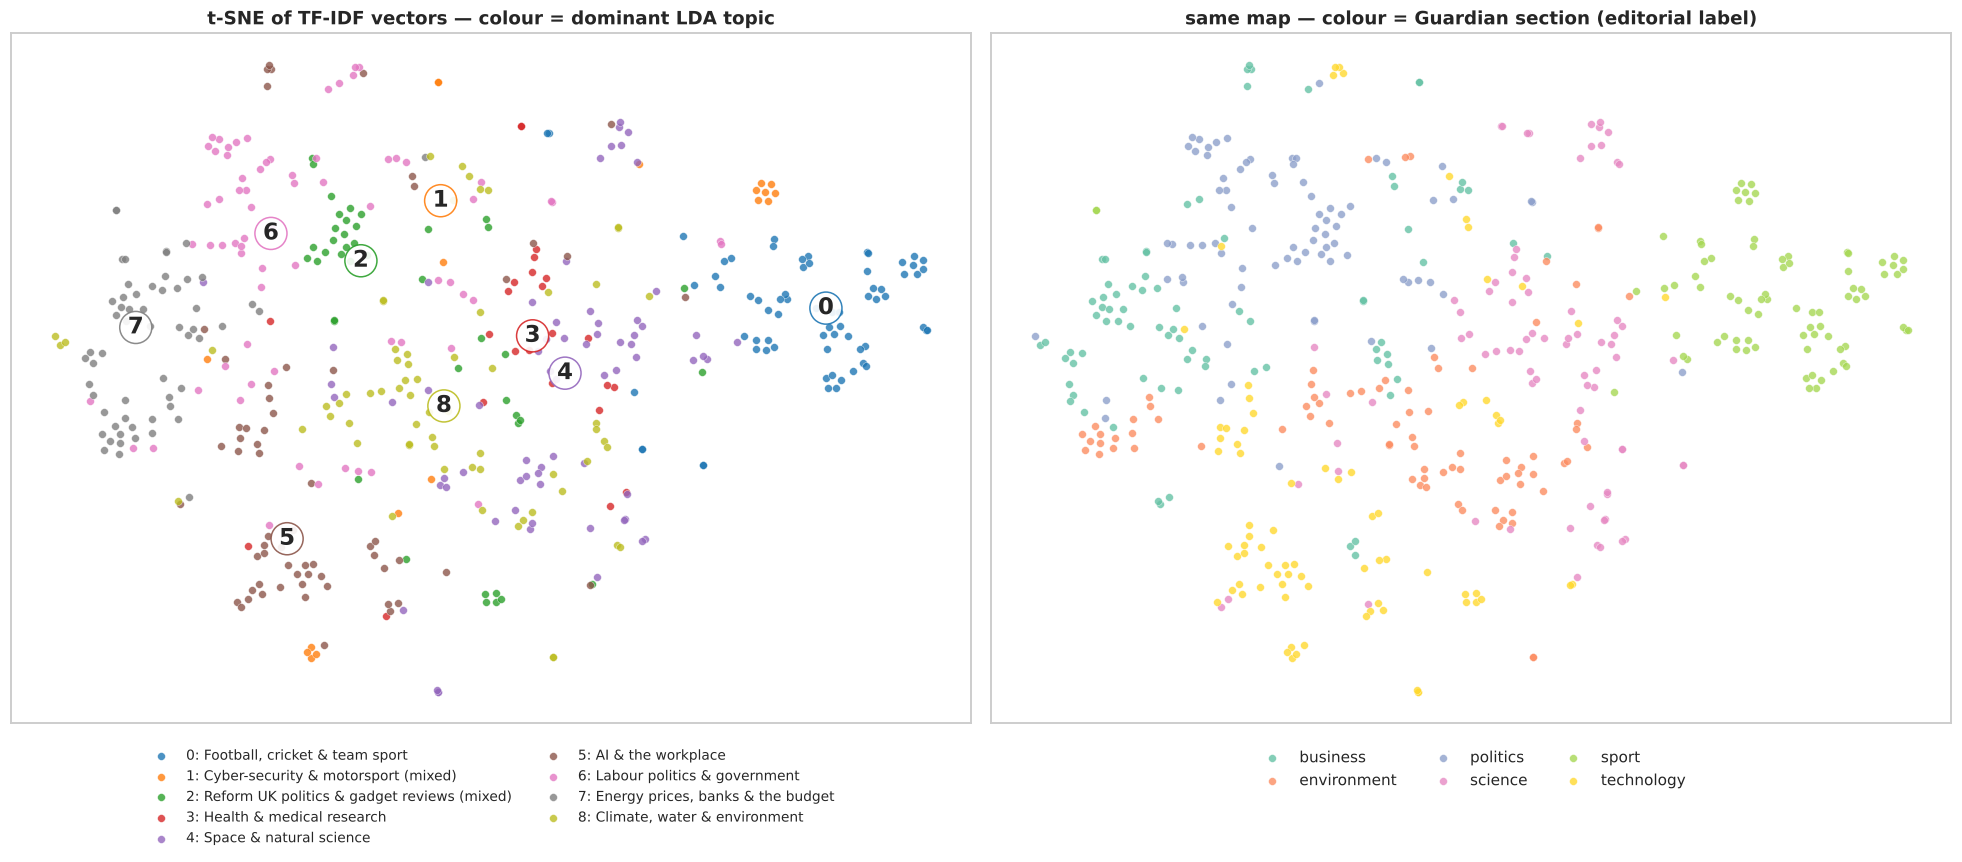

In [41]:
topic_pal = sns.color_palette("tab10", K)
labels_topic = news["topic"].values
sections = sorted(news["section"].unique())
sec_pal = dict(zip(sections, sns.color_palette("Set2", len(sections))))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax = axes[0]
for t in range(K):
    m = labels_topic == t
    ax.scatter(emb_tfidf[m, 0], emb_tfidf[m, 1], s=26, color=topic_pal[t], alpha=.8, label=f"{t}: {TOPIC_NAMES[t]}", edgecolor="white", linewidth=.3)
    cx, cy = np.median(emb_tfidf[m], axis=0)
    ax.text(cx, cy, str(t), fontsize=15, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=topic_pal[t], alpha=.9))
ax.set_title("t-SNE of TF-IDF vectors — colour = dominant LDA topic"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=9, frameon=False)
ax = axes[1]
for sec in sections:
    m = (news["section"] == sec).values
    ax.scatter(emb_tfidf[m, 0], emb_tfidf[m, 1], s=26, color=sec_pal[sec], alpha=.8, label=sec, edgecolor="white", linewidth=.3)
ax.set_title("same map — colour = Guardian section (editorial label)"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=10, frameon=False)
plt.tight_layout(); save_fig("05_tsne_topics_and_sections"); plt.show()

## 5.2 Do the topics really form clusters? — numbers instead of impressions
* **Silhouette score** (−1…+1): how much closer a document is to its own group than to the other groups (≥ 0.25 means clear structure, ≈ 0 means overlapping groups).
* **k-NN purity**: the share of a document's 10 nearest neighbours *in the 2-D map* that carry the same label. We also print the **chance level** (what random neighbours would give), and a normalised score
  `(purity − chance) / (1 − chance)`: 0 = no better than chance, 1 = perfect.

In [42]:
def knn_purity(emb, labels, k=10):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(emb).kneighbors(emb, return_distance=False)[:, 1:]
    return float((labels[idx] == labels[:, None]).mean())

def chance_level(labels):
    p = np.bincount(pd.factorize(labels)[0]) / len(labels)
    return float((p ** 2).sum())

def cluster_report(emb, labels_dict, name):
    rows = []
    for lname, lab in labels_dict.items():
        lab = np.asarray(lab)
        pur, ch = knn_purity(emb, pd.factorize(lab)[0]), chance_level(lab)
        rows.append({"map": name, "coloured by": lname, "silhouette": silhouette_score(emb, lab), "10-NN purity": pur,
                     "chance": ch, "normalised purity": (pur - ch) / (1 - ch)})
    return rows

label_sets = {"LDA topic": news["topic"].values, "Guardian section": news["section"].values}
rep_rows = cluster_report(emb_tfidf, label_sets, "t-SNE (TF-IDF)")
display(pd.DataFrame(rep_rows).set_index(["map", "coloured by"]).round(3))

silhouette  10-NN purity  chance  normalised purity
map            coloured by                                                          
t-SNE (TF-IDF) LDA topic              0.071         0.582   0.125              0.522
               Guardian section       0.128         0.696   0.167              0.635

## 5.3 Sensitivity to the perplexity parameter

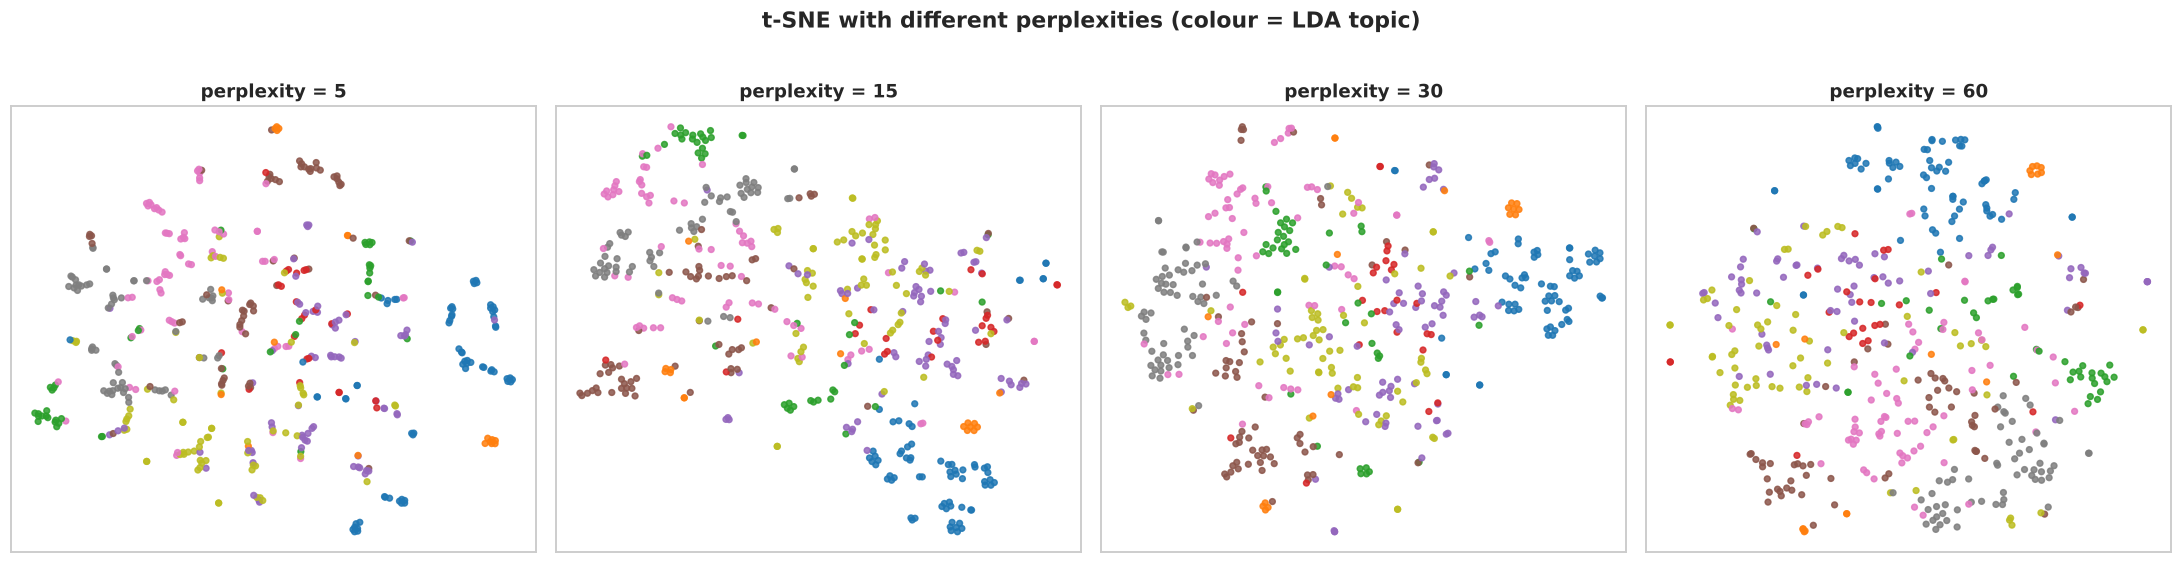

In [43]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, perp in zip(axes, [5, 15, 30, 60]):
    e = emb_tfidf if perp == 30 else run_tsne(X_svd, perp)
    ax.scatter(e[:, 0], e[:, 1], s=14, c=[topic_pal[t] for t in labels_topic], alpha=.85)
    ax.set_title(f"perplexity = {perp}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("t-SNE with different perplexities (colour = LDA topic)", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig("05_tsne_perplexity"); plt.show()

## 5.4 Alternative representation: Word2Vec document vectors
The task allows TF-IDF **or** Word2Vec. We repeat the experiment with Word2Vec (trained on the 478 articles, document = mean of word vectors) to see whether the representation changes the picture.

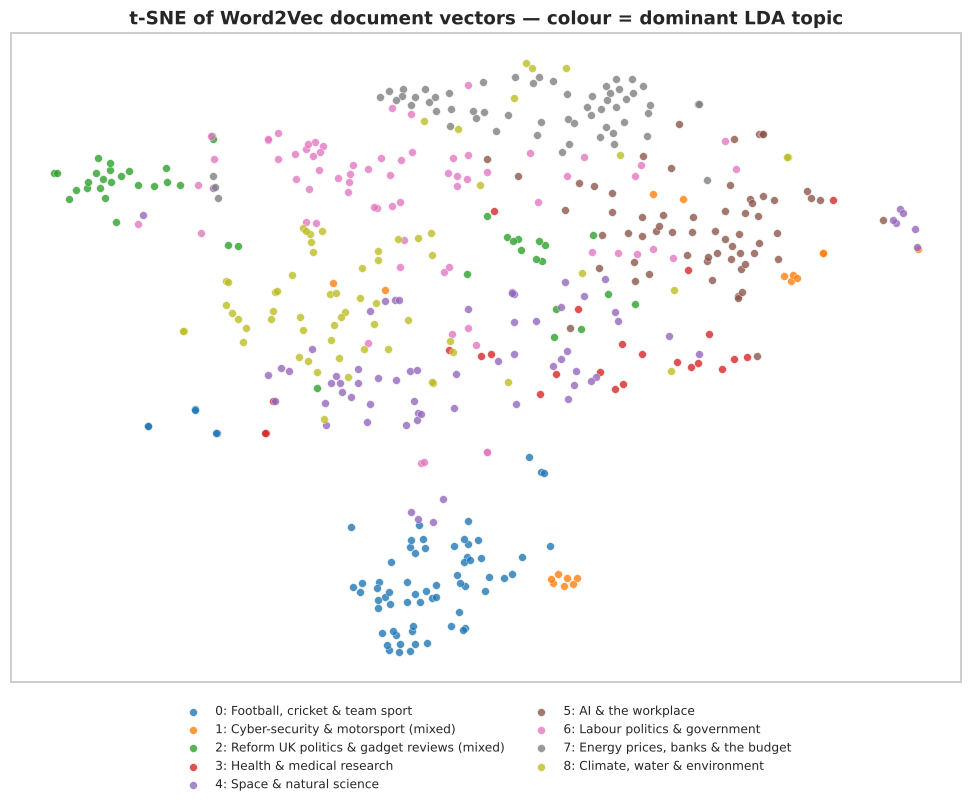

silhouette  10-NN purity  chance  normalised purity
map                      coloured by                                                          
t-SNE (TF-IDF)           LDA topic              0.071         0.582   0.125              0.522
                         Guardian section       0.128         0.696   0.167              0.635
t-SNE (Word2Vec)         LDA topic              0.135         0.641   0.125              0.589
                         Guardian section       0.191         0.709   0.167              0.651
TF-IDF space (100-d SVD) LDA topic              0.072           NaN   0.125                NaN

In [44]:
w2v_news = Word2Vec(sentences=news["lda_tokens"].tolist(), vector_size=100, window=5, min_count=3, sg=1, negative=10, epochs=30, seed=SEED, workers=1)
X_w2v_news = np.vstack([doc_vector(t, w2v_news) for t in news["lda_tokens"]])
emb_w2v = run_tsne(X_w2v_news, 30)

fig, ax = plt.subplots(figsize=(9, 7.5))
for t in range(K):
    m = labels_topic == t
    ax.scatter(emb_w2v[m, 0], emb_w2v[m, 1], s=26, color=topic_pal[t], alpha=.8, label=f"{t}: {TOPIC_NAMES[t]}", edgecolor="white", linewidth=.3)
ax.set_title("t-SNE of Word2Vec document vectors — colour = dominant LDA topic"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); save_fig("05_tsne_word2vec"); plt.show()

rep_rows += cluster_report(emb_w2v, label_sets, "t-SNE (Word2Vec)")
# reference: the same measures in the ORIGINAL (not reduced) space
rep_rows += [{"map": "TF-IDF space (100-d SVD)", "coloured by": "LDA topic", "silhouette": silhouette_score(X_svd, news["topic"].values, metric="cosine"),
              "10-NN purity": np.nan, "chance": chance_level(news["topic"].values), "normalised purity": np.nan}]
tsne_summary = pd.DataFrame(rep_rows).set_index(["map", "coloured by"])
display(tsne_summary.round(3))

**Interpretation of Module 5**

* **Topics do form neighbourhoods, but not isolated islands.** 58 % of a document's 10 nearest neighbours in the map share its LDA topic, against 12.5 % expected by chance (normalised purity 0.52). The silhouette is low (≈ 0.07) because topics overlap and are not compact round blobs — expected for text, where an article can touch several themes.
* **Clear groups on the map:** *Football, cricket & team sport* (0) is a well-separated island at the right edge; *Energy prices, banks & the budget* (7), *AI & the workplace* (5) and *Labour politics* (6) form compact regions on the left; the tight orange micro-clusters are the PHP-flaw articles, i.e. many articles about the *same story* (topic 1).
* **Overlapping groups:** *Health research* (3), *Space & natural science* (4) and *Climate, water & environment* (8) intermingle in the centre — they are all "science and nature" journalism with a shared vocabulary (*study, research, climate, scientist*). The same overlap is seen with the Guardian sections (science ↔ environment).
* **Editorial sections** are slightly better separated than LDA topics (normalised purity 0.64 vs 0.52): sections are coarse, topics are finer, so neighbours of an article more often share a section than a fine topic.
* **Word2Vec** gives a somewhat clearer map than TF-IDF (silhouette 0.135 vs 0.071; normalised purity 0.59 vs 0.52): its dense vectors link articles that use *related* rather than identical words.
* **Perplexity.** With perplexity 5 the map breaks into many tiny fragments (only the very closest neighbours count); with 60 the groups merge into one cloud with a looser arrangement. 15–30 shows the topic structure best, which is why 30 was used. The overall picture (sport island, compact economy/AI groups, central overlap of science topics) is stable.
* **Why dimensionality reduction helps here:** the 4,051-dimensional TF-IDF space cannot be inspected; the 2-D map immediately showed which topics are distinct and which are confused, something the keyword table alone could not.

---
# Module 6. Named Entity Recognition (NER) and Entity Linking (dataset 2 — news articles)

* **NER** finds *mentions* in text and gives each a type — "Keir Starmer" → `PERSON`, "Treasury" → `ORG`. The output is still just a string with a label.
* **Entity Linking (EL)** decides *which real-world entity* the mention refers to and connects it to an entry of a knowledge base (an ID, a description, a Wikipedia/Wikidata page).
  This resolves ambiguity ("Washington" = a city, a state, a person) and merges variants of the same entity ("Trump", "Donald Trump").

We use spaCy's statistical NER (`en_core_web_sm`) for the five requested types — **PERSON, ORG, GPE, DATE, MONEY** — on the *original* text (capital letters are crucial for NER, so we do not use the lowercased lemmas).

## 6.1 Applying spaCy NER
The small model makes a few systematic mistakes on tech news — it reads *AI* as a country/place (GPE) and tags companies such as *OpenAI* or *SpaceX* as people. We correct such
known cases with a spaCy **EntityRuler** (a rule-based component placed *before* the statistical NER; its entities are respected by the model). The effect is measured in 6.4.

In [45]:
from spacy import displacy

NER_LABELS = ["PERSON", "ORG", "GPE", "DATE", "MONEY"]
RULE_ORGS = ["OpenAI", "Anthropic", "SpaceX", "Palantir", "DeepMind", "Nvidia", "xAI", "Google DeepMind"]

nlp_ner = spacy.load("en_core_web_sm", exclude=["lemmatizer"])
ruler = nlp_ner.add_pipe("entity_ruler", before="ner")
ruler.add_patterns([{"label": "TECH_TERM", "pattern": [{"TEXT": "AI"}]},
                    {"label": "EVENT", "pattern": [{"TEXT": "Brexit"}]}] +
                   [{"label": "ORG", "pattern": name} for name in RULE_ORGS])

def normalise_mention(ent, label):
    s = ent.text.strip()
    s = re.sub(r"^(the|The)\s+", "", s)
    s = re.sub(r"[’']s$", "", s)
    if label == "MONEY" and ent.start_char > 0 and ent.doc.text[ent.start_char - 1] in "£$€":
        s = ent.doc.text[ent.start_char - 1] + s          # keep the currency sign that spaCy left out
    return s.strip()

t0 = time.time()
records = []
for doc_id, section, doc in zip(news["doc_id"], news["section"], nlp_ner.pipe(news["text"], batch_size=16, disable=["parser"])):
    for ent in doc.ents:
        if ent.label_ in NER_LABELS:
            mention = normalise_mention(ent, ent.label_)
            if mention:
                records.append({"doc_id": doc_id, "section": section, "mention": mention, "label": ent.label_, "start_char": ent.start_char})
ents = pd.DataFrame(records)
print(f"NER on {len(news)} articles in {time.time() - t0:.0f}s -> {len(ents):,} entity mentions, {ents[['mention', 'label']].drop_duplicates().shape[0]:,} distinct (mention, type) pairs")

NER on 478 articles in 19s -> 23,293 entity mentions, 8,487 distinct (mention, type) pairs


### Extracted entities and their categories — one article in detail

In [46]:
demo_doc_id = news.loc[news["section"] == "politics", "doc_id"].iloc[1]
demo_text = news.loc[news["doc_id"] == demo_doc_id, "text"].iloc[0][:900]
demo_nlp = nlp_ner(demo_text)
print("Article:", news.loc[news["doc_id"] == demo_doc_id, "headline"].iloc[0], "\n")
displacy.render(demo_nlp, style="ent", jupyter=True, options={"ents": NER_LABELS, "colors": {
    "PERSON": "#ffd6a5", "ORG": "#caffbf", "GPE": "#9bf6ff", "DATE": "#bdb2ff", "MONEY": "#fdffb6"}})

table = pd.DataFrame([{"entity": e.text, "category": e.label_, "meaning": spacy.explain(e.label_)} for e in demo_nlp.ents if e.label_ in NER_LABELS])
display(table)

Article: Starmer says UK must get closer to Europe as US relationship changes 



,entity,category,meaning
0,Starmer,ORG,"Companies, agencies, institutions, etc."
1,UK,GPE,"Countries, cities, states"
2,US,GPE,"Countries, cities, states"
3,UK,GPE,"Countries, cities, states"
4,US,GPE,"Countries, cities, states"
5,Keir Starmer,PERSON,"People, including fictional"
6,Russia,GPE,"Countries, cities, states"
7,Washington,GPE,"Countries, cities, states"
8,Donald Trump’s,PERSON,"People, including fictional"
9,the Oval Office,ORG,"Companies, agencies, institutions, etc."


### Entities in the whole collection

,mentions,distinct
label,,
PERSON,5869,2965
ORG,6807,2535
GPE,4420,747
DATE,5322,1631
MONEY,875,609


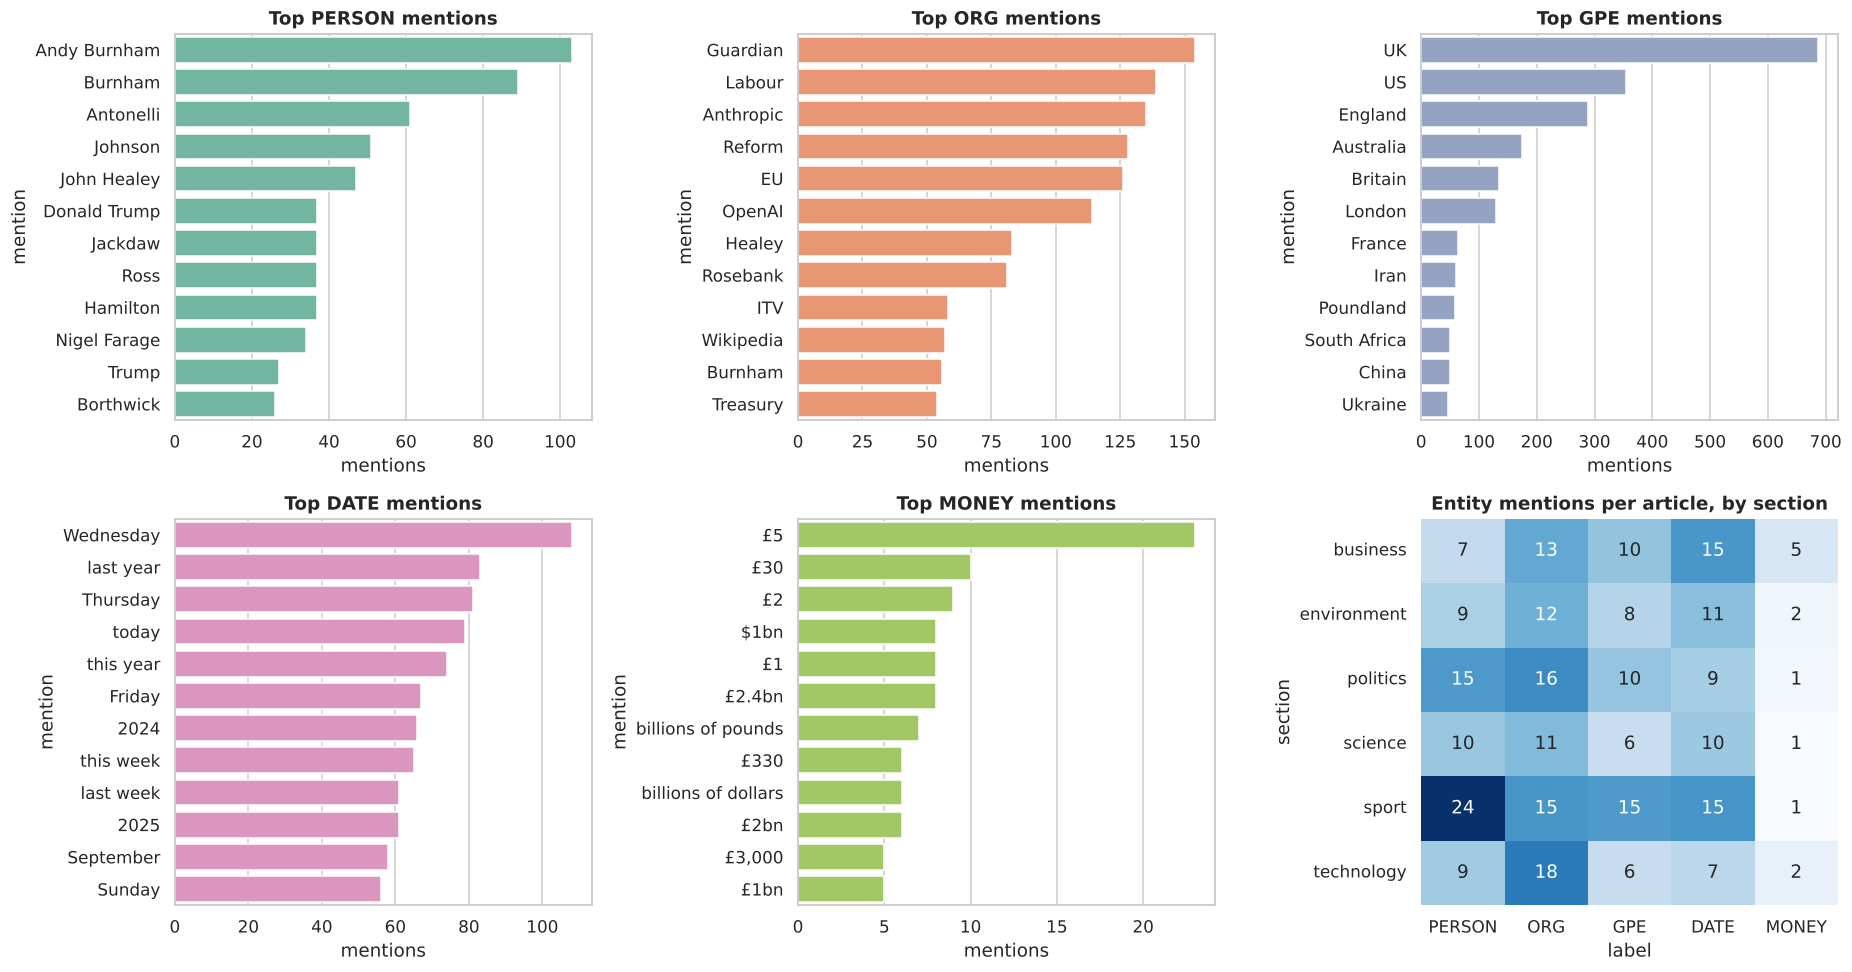

In [47]:
label_counts = ents.groupby("label").agg(mentions=("mention", "size"), distinct=("mention", "nunique")).reindex(NER_LABELS)
display(label_counts)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
lab_colors = dict(zip(NER_LABELS, sns.color_palette("Set2", 5)))
for ax, lab in zip(axes.ravel(), NER_LABELS):
    top = ents.loc[ents["label"] == lab, "mention"].value_counts().head(12)
    sns.barplot(x=top.values, y=top.index, color=lab_colors[lab], ax=ax)
    ax.set_title(f"Top {lab} mentions"); ax.set_xlabel("mentions")
dens = ents.groupby(["section", "label"]).size().unstack().reindex(columns=NER_LABELS).fillna(0)
dens = dens.div(news["section"].value_counts(), axis=0)
sns.heatmap(dens, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[1, 2])
axes[1, 2].set_title("Entity mentions per article, by section")
plt.tight_layout(); save_fig("06_ner_entities"); plt.show()

## 6.2 Entity Linking — a basic knowledge-base approach

**Idea.** For every `PERSON`, `ORG` and `GPE` mention we look for the matching entry in a knowledge base (KB). (`DATE` and `MONEY` are values, not things with a KB entry, so they are not linked.)

1. **Normalise** the mention (lowercase, remove accents, "the", "'s", titles like *Sir*).
2. **Candidate generation:** exact match against the *aliases* of KB entries; if none, a fuzzy match (similarity ≥ 95 %) to catch spelling variants.
3. **Candidate ranking** for ambiguous aliases: score = match quality + type agreement with spaCy's label + **context overlap** (words that characterise the KB entry also occur in the same article).
   Surnames such as *Johnson* or *Hamilton* are only linked when the context supports it.
4. **NIL:** if nothing scores high enough, the mention is left unlinked.
5. **External database (optional step):** the most frequent unlinked mentions are looked up in **Wikidata** through its public search API (results cached in `data/wikidata_cache.json`); a candidate is accepted
   only if its label matches the mention and its description fits the entity type (a *person* must be described as a politician/player/…, a *GPE* as a country/city/…).

**Knowledge base.** (a) all countries from the `pycountry` ISO list; (b) a hand-built list of ~150 people, organisations and places that dominate our collection (each with aliases, a short neutral description and a Wikipedia URL).

In [48]:
import unicodedata, pycountry
from rapidfuzz import process, fuzz

KB = []

def kb_add(name, typ, aliases=(), desc="", keywords=(), needs_context=False, url=None):
    KB.append({"kb_id": f"KB{len(KB) + 1:04d}", "name": name, "type": typ, "aliases": {name, *aliases}, "description": desc,
               "keywords": set(keywords), "needs_context": needs_context,
               "url": url or "https://en.wikipedia.org/wiki/" + name.replace(" ", "_")})

# (a) countries from ISO 3166
COUNTRY_ALIASES = {"Russian Federation": ["Russia"], "Türkiye": ["Turkey"], "Turkey": ["Turkiye"], "Viet Nam": ["Vietnam"], "Czechia": ["Czech Republic"],
                   "Korea, Republic of": ["South Korea"], "Korea, Democratic People's Republic of": ["North Korea"],
                   "Taiwan, Province of China": ["Taiwan"], "Palestine, State of": ["Palestine"], "Côte d'Ivoire": ["Ivory Coast"],
                   "Congo, The Democratic Republic of the": ["DR Congo", "Democratic Republic of the Congo"]}
for c in pycountry.countries:
    al = {getattr(c, a) for a in ("name", "official_name", "common_name") if hasattr(c, a)}
    if "," in c.name and not c.name.startswith(("Korea", "Congo")):
        al.add(c.name.split(",")[0])                    # "Iran, Islamic Republic of" -> "Iran"
    al.update(COUNTRY_ALIASES.get(c.name, []))
    kb_add(c.name, "GPE", al, f"Country (ISO 3166-1: {c.alpha_2})")

# (b) hand-built part
PEOPLE = [  # name, aliases, description, context keywords, needs_context
    ("Donald Trump", ["Trump", "Donald J. Trump"], "American businessman and politician", ["president", "white", "house", "republican", "tariff"], False),
    ("Keir Starmer", ["Starmer", "Sir Keir Starmer"], "British Labour politician and lawyer", ["labour", "downing", "minister", "government"], False),
    ("Andy Burnham", ["Burnham", "Andrew Burnham"], "British Labour politician", ["labour", "manchester", "minister", "mayor"], False),
    ("Nigel Farage", ["Farage", "Nige"], "British politician associated with Brexit and Reform UK", ["reform", "brexit", "party"], False),
    ("John Healey", ["Healey"], "British Labour politician", ["labour", "minister", "budget", "defence"], False),
    ("Wes Streeting", ["Streeting"], "British Labour politician", ["labour", "health", "minister"], False),
    ("Boris Johnson", ["Johnson"], "British Conservative politician", ["boris", "conservative", "tory", "brexit", "minister", "downing"], True),
    ("Rishi Sunak", ["Sunak"], "British Conservative politician", ["conservative", "tory", "minister"], False),
    ("Kemi Badenoch", ["Badenoch"], "British Conservative politician", ["conservative", "tory", "party"], False),
    ("Rachel Reeves", ["Reeves"], "British Labour politician", ["labour", "chancellor", "budget", "treasury"], False),
    ("John Swinney", ["Swinney"], "Scottish politician, Scottish National Party", ["snp", "scotland", "scottish", "holyrood"], False),
    ("Zia Yusuf", ["Yusuf"], "British businessman and politician associated with Reform UK", ["reform", "party", "farage"], False),
    ("Joe Biden", ["Biden"], "American politician", ["president", "democrat", "white", "house"], False),
    ("Vladimir Putin", ["Putin"], "Russian politician", ["russia", "kremlin", "ukraine"], False),
    ("Volodymyr Zelensky", ["Zelensky", "Zelenskyy", "Volodymyr Zelenskyy"], "Ukrainian politician", ["ukraine", "kyiv", "war"], False),
    ("Emmanuel Macron", ["Macron"], "French politician", ["france", "french", "paris"], False),
    ("Xi Jinping", ["Xi"], "Chinese politician", ["china", "chinese", "beijing"], False),
    ("Benjamin Netanyahu", ["Netanyahu"], "Israeli politician", ["israel", "gaza", "israeli"], False),
    ("Elon Musk", ["Musk"], "Businessman associated with Tesla, SpaceX and X", ["tesla", "spacex", "space", "twitter", "billionaire"], False),
    ("Sam Altman", ["Altman"], "American entrepreneur associated with OpenAI", ["openai", "chatgpt", "ai"], False),
    ("Mark Zuckerberg", ["Zuckerberg"], "American businessman, co-founder of Facebook", ["meta", "facebook"], False),
    ("Jeff Bezos", ["Bezos"], "American businessman, founder of Amazon", ["amazon"], False),
    ("Lewis Hamilton", ["Hamilton"], "British racing driver", ["formula", "ferrari", "mercedes", "grand", "prix", "driver", "race"], True),
    ("Kimi Antonelli", ["Antonelli", "Andrea Kimi Antonelli"], "Italian racing driver", ["formula", "mercedes", "grand", "prix", "driver", "race"], False),
    ("Jay-Z", ["Jay Z"], "American rapper and businessman", ["rapper", "music", "roc"], False),
]
for name, al, desc, kw, ctx in PEOPLE:
    kb_add(name, "PERSON", al, desc, kw, ctx)

ORGS = [
    ("European Union", ["EU", "E.U."], "Political and economic union of European states", []),
    ("United Nations", ["UN", "U.N."], "International organisation of states", []),
    ("NATO", ["North Atlantic Treaty Organization"], "Military alliance of North American and European states", []),
    ("National Health Service", ["NHS"], "Publicly funded healthcare systems of the United Kingdom", []),
    ("BBC", ["British Broadcasting Corporation"], "British public service broadcaster", []),
    ("ITV", ["ITV plc"], "British commercial television broadcaster", []),
    ("The Guardian", ["Guardian", "Guardian News & Media"], "British daily newspaper", []),
    ("Reuters", [], "International news agency", []),
    ("Wikipedia", [], "Free online encyclopedia", []),
    ("Labour Party", ["Labour", "Labour Party (UK)"], "Political party in the United Kingdom", []),
    ("Conservative Party", ["Conservatives", "Tories", "Conservative Party (UK)"], "Political party in the United Kingdom", []),
    ("Reform UK", ["Reform", "Reform Party"], "Political party in the United Kingdom", ["farage", "party"]),
    ("Scottish National Party", ["SNP"], "Political party in Scotland", []),
    ("Liberal Democrats", ["Lib Dems", "Lib Dem"], "Political party in the United Kingdom", []),
    ("Green Party of England and Wales", ["Greens", "Green Party"], "Political party in England and Wales", []),
    ("Plaid Cymru", [], "Political party in Wales", []),
    ("HM Treasury", ["Treasury", "The Treasury"], "Economics and finance ministry of the United Kingdom", []),
    ("Bank of England", [], "Central bank of the United Kingdom", []),
    ("Federal Reserve", ["Fed", "Federal Reserve System"], "Central banking system of the United States", []),
    ("International Monetary Fund", ["IMF"], "International financial institution", []),
    ("World Bank", [], "International financial institution", []),
    ("World Health Organization", ["WHO"], "United Nations agency for public health", []),
    ("FIFA", [], "International governing body of association football", []),
    ("UEFA", [], "Governing body of European football", []),
    ("Premier League", [], "Top-tier English football league", []),
    ("National Football League", ["NFL"], "American professional football league", []),
    ("International Cricket Council", ["ICC"], "Governing body of international cricket", []),
    ("Unison", ["UNISON"], "British trade union", []),
    ("Google", ["Google LLC"], "American technology company", []),
    ("Microsoft", [], "American technology company", []),
    ("Apple Inc.", ["Apple"], "American technology company", ["iphone", "app", "device", "tech"]),
    ("Amazon (company)", ["Amazon"], "American technology and retail company", ["prime", "aws", "bezos", "delivery"]),
    ("Meta Platforms", ["Meta", "Facebook"], "American technology company", []),
    ("OpenAI", [], "American artificial intelligence company", []),
    ("Anthropic", [], "American artificial intelligence company", []),
    ("Tesla, Inc.", ["Tesla"], "American electric vehicle company", ["musk", "car", "electric"]),
    ("SpaceX", [], "American aerospace company", []),
    ("Nvidia", ["NVIDIA"], "American semiconductor company", []),
    ("Palantir Technologies", ["Palantir"], "American software company", []),
    ("Mercedes-Benz Group", ["Mercedes"], "German automotive company", ["car", "formula", "team", "motor"]),
    ("Poundland", [], "British discount retailer", []),
    ("NASA", [], "United States space agency", []),
    ("TikTok", [], "Short-video social media platform", []),
    ("Shell plc", ["Shell"], "British multinational oil and gas company", ["oil", "gas", "energy"]),
    ("Thames Water", [], "Water and sewerage company in England", []),
    ("Environmental Protection Agency", ["EPA"], "United States federal environmental agency", []),
    ("Rosebank oil field", ["Rosebank"], "Proposed oil and gas field in the North Sea west of Shetland", []),
]
for name, al, desc, kw in ORGS:
    kb_add(name, "ORG", al, desc, kw, False)

PLACES = [
    ("United Kingdom", ["UK", "U.K.", "Britain", "Great Britain", "United Kingdom of Great Britain and Northern Ireland"], "Sovereign country in north-western Europe", [], False),
    ("United States", ["US", "U.S.", "USA", "America", "United States of America"], "Country in North America", [], False),
    ("England", [], "Country that is part of the United Kingdom", [], False),
    ("Scotland", [], "Country that is part of the United Kingdom", [], False),
    ("Wales", [], "Country that is part of the United Kingdom", [], False),
    ("Northern Ireland", [], "Country that is part of the United Kingdom", [], False),
    ("London", [], "Capital city of England and the United Kingdom", [], False),
    ("Manchester", [], "City in North West England", [], False),
    ("Birmingham", [], "City in the West Midlands, England", [], False),
    ("Glasgow", [], "City in Scotland", [], False),
    ("Edinburgh", [], "Capital city of Scotland", [], False),
    ("Paris", [], "Capital city of France", [], False),
    ("Brussels", [], "Capital city of Belgium", [], False),
    ("Berlin", [], "Capital city of Germany", [], False),
    ("Beijing", [], "Capital city of China", [], False),
    ("Moscow", [], "Capital city of Russia", [], False),
    ("Kyiv", ["Kiev"], "Capital city of Ukraine", [], False),
    ("Tehran", [], "Capital city of Iran", [], False),
    ("Gaza Strip", ["Gaza"], "Palestinian territory on the Mediterranean coast", [], False),
    ("New York City", ["New York"], "Most populous city in the United States", ["york", "manhattan", "wall", "street", "city"], False),
    ("Washington, D.C.", ["Washington", "Washington DC"], "Capital city of the United States", ["white", "house", "trump", "congress", "senate", "tariff", "federal", "administration", "president", "capitol"], False),
    ("Washington (state)", ["Washington"], "State in the north-western United States", ["seattle", "state", "oregon", "pacific", "tacoma", "northwest", "rain"], False),
    ("Sydney", [], "City in Australia", [], False),
    ("Melbourne", [], "City in Australia", [], False),
    ("Milwaukee", [], "City in Wisconsin, United States", [], False),
]
for name, al, desc, kw, ctx in PLACES:
    kb_add(name, "GPE", al, desc, kw, ctx)

# the countries from pycountry get extra short aliases already covered above (e.g. "Russia", "Iran")
print(f"Knowledge base: {len(KB)} entries  ({collections.Counter(e['type'] for e in KB)})")

Knowledge base: 346 entries  (Counter({'GPE': 274, 'ORG': 47, 'PERSON': 25}))


In [49]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"^(the|mr|mrs|ms|dr|sir|dame|lord|prof|professor)\s+", "", s)
    s = re.sub(r"'s$", "", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

alias_index = collections.defaultdict(list)
for i, e in enumerate(KB):
    for a in e["aliases"]:
        alias_index[norm(a)].append(i)
alias_keys = list(alias_index)

doc_context = {d: set(t) for d, t in zip(news["doc_id"], news["tokens"])}     # lemma set of every article

def link_mention(mention, label, doc_id=None, threshold=0.8):
    """Return (kb_index, score, method) or None."""
    key = norm(mention)
    if not key:
        return None
    cands, method = alias_index.get(key, []), "kb-exact"
    if not cands and len(key) >= 5:
        hit = process.extractOne(key, alias_keys, scorer=fuzz.ratio, score_cutoff=95)
        if hit:
            cands, method = alias_index[hit[0]], "kb-fuzzy"
    best = None
    ctx = doc_context.get(doc_id, set())
    for i in cands:
        e = KB[i]
        sc = 1.0 if method == "kb-exact" else 0.9
        sc += 0.3 if e["type"] == label else -0.3
        overlap = len(e["keywords"] & ctx)
        sc += 0.15 * min(overlap, 4)
        if e["needs_context"] and overlap == 0:
            sc -= 1.0
        if best is None or sc > best[1]:
            best = (i, sc, method)
    return best if best and best[1] >= threshold else None

# --- demo: why linking is more than string matching (ambiguity) ---
demo_sentences = [
    "Washington announced new tariffs after talks at the White House with Donald Trump.",
    "Heavy rain hit Seattle and the rest of Washington state on Tuesday.",
    "Johnson told the Conservative conference that Brexit would be completed.",
    "Johnson scored twice in the match on Saturday.",
]
rows = []
for sent in demo_sentences:
    d = nlp_ner(sent)
    ctx = {t.lemma_.lower() for t in nlp(clean_text(sent))}
    for e in d.ents:
        if e.label_ in ("PERSON", "ORG", "GPE"):
            doc_context[-1] = ctx
            r = link_mention(e.text, e.label_, -1)
            rows.append({"sentence": sent[:62] + "...", "mention": e.text, "NER label": e.label_,
                         "linked to": KB[r[0]]["name"] if r else "NIL (not linked)", "score": round(r[1], 2) if r else None})
display(pd.DataFrame(rows))

,sentence,mention,NER label,linked to,score
0,Washington announced new tariffs after talks at the White Hous...,Washington,GPE,"Washington, D.C.",1.90
1,Washington announced new tariffs after talks at the White Hous...,Donald Trump,PERSON,Donald Trump,1.75
2,Heavy rain hit Seattle and the rest of Washington state on Tue...,Seattle,GPE,NIL (not linked),NaN
3,Heavy rain hit Seattle and the rest of Washington state on Tue...,Washington,GPE,Washington (state),1.75
4,Johnson told the Conservative conference that Brexit would be ...,Johnson,PERSON,Boris Johnson,1.60
5,Johnson scored twice in the match on Saturday....,Johnson,PERSON,NIL (not linked),NaN


The same string *Washington* is linked to **Washington, D.C.** when the sentence is about the White House and tariffs, and to **Washington (state)** when it is about Seattle and rain; *Johnson* is linked to Boris Johnson only
when the context talks about Conservatives and Brexit. This is exactly what separates **entity linking** from plain NER (which would just say `GPE` or `PERSON` in both cases).

## 6.3 Link every entity of the collection

In [50]:
link_types = ["PERSON", "ORG", "GPE"]
mentions = ents[ents["label"].isin(link_types)].copy()

results = {}
for (mention, label, doc_id) in mentions[["mention", "label", "doc_id"]].drop_duplicates().itertuples(index=False):
    results[(mention, label, doc_id)] = link_mention(mention, label, doc_id)

mentions["hit"] = [results[(m, l, d)] for m, l, d in zip(mentions["mention"], mentions["label"], mentions["doc_id"])]
mentions["kb_idx"] = [h[0] if h else None for h in mentions["hit"]]
mentions["score"] = [h[1] if h else None for h in mentions["hit"]]
mentions["method"] = [h[2] if h else "NIL" for h in mentions["hit"]]
mentions["kb_name"] = [KB[int(i)]["name"] if pd.notna(i) else None for i in mentions["kb_idx"]]
mentions["kb_url"] = [KB[int(i)]["url"] if pd.notna(i) else None for i in mentions["kb_idx"]]
mentions["kb_description"] = [KB[int(i)]["description"] if pd.notna(i) else None for i in mentions["kb_idx"]]
print("linked with the local KB:", f"{(mentions['method'] != 'NIL').mean():.1%} of {len(mentions):,} mentions")

linked with the local KB: 33.6% of 17,096 mentions


In [51]:
# Optional external step: Wikidata for the most frequent NIL mentions
import requests

USE_WIKIDATA = True
WD_CACHE_FILE = DATA / "wikidata_cache.json"
WD_API = "https://www.wikidata.org/w/api.php"
WD_HEADERS = {"User-Agent": "nlp-midterm-student-project/1.0 (educational use)"}
WD_FIT = {
    "PERSON": re.compile(r"politician|footballer|player|actor|actress|singer|rapper|business|journalist|writer|scientist|driver|cricketer|coach|presenter|minister|activist|economist|lawyer|judge|musician|comedian|manager|executive|\b(1[89]|20)\d\d\b"),
    "ORG": re.compile(r"company|organi[sz]ation|party|agency|newspaper|club|university|bank|government|department|broadcaster|institution|union|corporation|retailer|team|association|authority|service|council|charity|manufacturer|firm|network|channel|league|committee|publisher|website|brand|trust|charity"),
    "GPE": re.compile(r"country|city|capital|town|state|region|county|village|borough|municipality|territory|province|district|nation|island|sovereign|suburb|constituency"),
}
wd_cache = json.loads(WD_CACHE_FILE.read_text()) if WD_CACHE_FILE.exists() else {}

def wikidata_lookup(mention, label):
    key = f"{label}|{mention}"
    if key in wd_cache:
        return wd_cache[key]
    r = requests.get(WD_API, params={"action": "wbsearchentities", "search": mention, "language": "en", "format": "json", "limit": 5, "type": "item"},
                     headers=WD_HEADERS, timeout=10)
    found = None
    for cand in r.json().get("search", []):
        desc = (cand.get("description") or "").lower()
        if cand.get("label", "").lower() == mention.lower() and WD_FIT[label].search(desc):
            found = {"id": cand["id"], "name": cand["label"], "description": cand.get("description", ""), "url": f"https://www.wikidata.org/wiki/{cand['id']}"}
            break
    wd_cache[key] = found
    time.sleep(0.15)
    return found

if USE_WIKIDATA:
    try:
        requests.get(WD_API, params={"action": "query", "meta": "siteinfo", "format": "json"}, headers=WD_HEADERS, timeout=6).raise_for_status()
    except Exception as e:
        USE_WIKIDATA = False
        print("⚠ Wikidata is not reachable from this machine -> external step skipped (", type(e).__name__, ")")

if USE_WIKIDATA:
    nil_top = (mentions[mentions["method"] == "NIL"].groupby(["mention", "label"]).size().reset_index(name="n")
               .query("n >= 3").sort_values("n", ascending=False).head(150))
    wd_found = {}
    for m, l in zip(nil_top["mention"], nil_top["label"]):
        try:
            wd_found[(m, l)] = wikidata_lookup(m, l)
        except Exception:
            wd_found[(m, l)] = None
    WD_CACHE_FILE.write_text(json.dumps(wd_cache, ensure_ascii=False, indent=1))
    for i, row in mentions[mentions["method"] == "NIL"].iterrows():
        hit = wd_found.get((row["mention"], row["label"]))
        if hit:
            mentions.loc[i, ["method", "kb_name", "kb_url", "kb_description"]] = ["wikidata", hit["name"], hit["url"], hit["description"]]
    print(f"Wikidata looked up {len(nil_top)} frequent unlinked mentions, accepted {sum(v is not None for v in wd_found.values())}")

⚠ Wikidata is not reachable from this machine -> external step skipped ( ProxyError )


source,local KB,Wikidata,NIL (not linked),total,linked %
label,,,,,
GPE,3054,0,1366,4420,69.1
ORG,2060,0,4747,6807,30.3
PERSON,626,0,5243,5869,10.7


Share of ALL mentions that were linked: 33.6%
Share of DISTINCT strings that were linked: 3.9%  (low, because thousands of strings occur only once)


Among the 100 most frequent strings of each type, % linked: {'GPE': 62.0, 'ORG': 39.0, 'PERSON': 20.0}


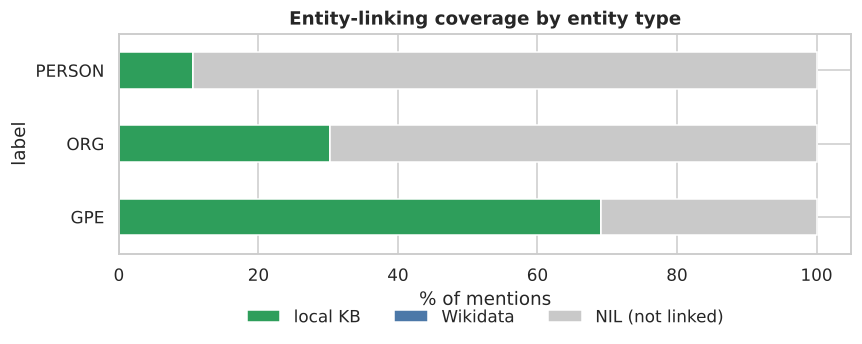

In [52]:
cov = (mentions.assign(source=mentions["method"].map(lambda m: "NIL (not linked)" if m == "NIL" else ("Wikidata" if m == "wikidata" else "local KB")))
       .groupby(["label", "source"]).size().unstack(fill_value=0).reindex(columns=["local KB", "Wikidata", "NIL (not linked)"], fill_value=0))
cov_pct = cov.div(cov.sum(axis=1), axis=0) * 100
display(cov.assign(total=cov.sum(axis=1), **{"linked %": (100 - cov_pct["NIL (not linked)"]).round(1)}))

uniq = mentions.drop_duplicates(["mention", "label"])
print("Share of ALL mentions that were linked:", f"{(mentions['method'] != 'NIL').mean():.1%}")
print("Share of DISTINCT strings that were linked:", f"{(uniq['method'] != 'NIL').mean():.1%}  (low, because thousands of strings occur only once)")
top100 = (mentions.groupby(["label", "mention"]).agg(n=("mention", "size"), linked=("method", lambda m: (m != "NIL").mean() > 0.5))
          .reset_index().sort_values("n", ascending=False).groupby("label").head(100))
print("Among the 100 most frequent strings of each type, % linked:", top100.groupby("label")["linked"].mean().mul(100).round(0).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.6))
cov_pct.plot(kind="barh", stacked=True, ax=ax, color=["#2e9e5b", "#4c78a8", "#c9c9c9"])
ax.set_xlabel("% of mentions"); ax.set_title("Entity-linking coverage by entity type"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.4), ncol=3, frameon=False)
plt.tight_layout(); save_fig("06_entity_linking_coverage"); plt.show()

In [53]:
# The most frequent linked entities with their knowledge-base entry (merged name variants)
linked = mentions[mentions["method"] != "NIL"]
top_linked = (linked.groupby(["kb_name", "label", "kb_description", "kb_url"]).agg(mentions=("mention", "size"), variants=("mention", lambda s: ", ".join(s.value_counts().index[:4])))
              .reset_index().sort_values("mentions", ascending=False).head(25))
display(top_linked[["kb_name", "label", "mentions", "variants", "kb_description"]].reset_index(drop=True))

,kb_name,label,mentions,variants,kb_description
0,United Kingdom,GPE,834,"UK, Britain, Great Britain",Sovereign country in north-western Europe
1,United States,GPE,375,"US, America, USA",Country in North America
2,England,GPE,289,England,Country that is part of the United Kingdom
3,Andy Burnham,PERSON,192,"Andy Burnham, Burnham",British Labour politician
4,Australia,GPE,174,Australia,Country (ISO 3166-1: AU)
5,The Guardian,ORG,154,Guardian,British daily newspaper
6,Labour Party,ORG,145,"Labour, Labour party",Political party in the United Kingdom
7,Anthropic,ORG,135,Anthropic,American artificial intelligence company
8,European Union,ORG,131,"EU, European Union",Political and economic union of European states
9,London,GPE,129,London,Capital city of England and the United Kingdom


In [54]:
# Frequent mentions that stayed unlinked — what the knowledge base lacks
nil = mentions[mentions["method"] == "NIL"].groupby(["mention", "label"]).size().reset_index(name="mentions").sort_values("mentions", ascending=False)
display(nil.head(20).reset_index(drop=True))

,mention,label,mentions
0,Poundland,GPE,59
1,Johnson,PERSON,42
2,Ross,PERSON,37
3,Jackdaw,PERSON,37
4,PHP,ORG,36
5,Borthwick,PERSON,26
6,Russell,PERSON,24
7,Northampton,GPE,23
8,Westminster,GPE,22
9,Gordon Brothers,PERSON,21


In [55]:
# Random sample of links with context for a manual precision check
rng = np.random.RandomState(SEED)
sample_idx = rng.choice(linked.index.values, size=min(30, len(linked)), replace=False)
text_by_doc = dict(zip(news["doc_id"], news["text"]))
chk = []
for i in sample_idx:
    r = linked.loc[i]
    t = text_by_doc[r["doc_id"]]; s = int(r["start_char"])
    chk.append({"mention": r["mention"], "type": r["label"], "linked to": r["kb_name"], "via": r["method"], "context": "…" + t[max(0, s - 70): s + len(r["mention"]) + 50].replace("\n", " ") + "…"})
manual_check = pd.DataFrame(chk)
display(manual_check)

,mention,type,linked to,via,context
0,Nato,ORG,NATO,kb-exact,"…sion,” the MPs said, and they argued that the UK, as the next largest Nato military in the region, had to..."
1,Ireland,GPE,Ireland,kb-exact,"…ailable on your mobile phone.” Donohoe, a former finance minister for Ireland, cited the example of India..."
2,India,GPE,India,kb-exact,…oadcast FTA since Channel 4 picked up the rights for a Test series in India in 2021 during the final Covi...
3,Microsoft,ORG,Microsoft,kb-exact,"…for and are in the process of obtaining a green card. “Our message to Microsoft is, you’re a great Americ..."
4,Anthropic,ORG,Anthropic,kb-exact,"… regulators for tougher rules to control AI, as well as warnings from Anthropic, Google DeepMind and Open..."
5,UK,GPE,United Kingdom,kb-exact,…Reform UK councillors and candidates filmed making racist a…
6,India,GPE,India,kb-exact,"…he price range, Jio would be worth 10.3tn rupees, which would make it India’s fourth-largest company, beh..."
7,Burnham,PERSON,Andy Burnham,kb-exact,"…” to run the FDP. Watson, a Labour peer and former minister alongside Burnham, was appointed as Palantir’..."
8,John Healey,PERSON,John Healey,kb-exact,…pected spending commitments. But on Thursday morning Andy Burnham and John Healey could afford themselves...
9,US,GPE,United States,kb-exact,"…Peter Thiel and the former Google CEO Eric Schmidt. Rohit Khanna, the US congressman representing Califor..."


## 6.4 Error analysis, NER quality and the effect of the rule-based fixes
We have no gold annotation, so quality is assessed by (a) how often the same string receives *different* labels, (b) the effect of the EntityRuler, (c) the manual precision check above.

In [56]:
lab_per_mention = ents.groupby("mention")["label"].nunique()
confused = ents[ents["mention"].isin(lab_per_mention[lab_per_mention > 1].index)]
conf_table = (confused.groupby(["mention", "label"]).size().unstack(fill_value=0).assign(total=lambda d: d.sum(axis=1))
              .sort_values("total", ascending=False).head(12))
print("Strings that received more than one label (top 12):")
display(conf_table)

# effect of the ruler on the first 150 articles: how was 'AI' / 'OpenAI' / 'Anthropic' labelled by the plain model?
sub = news["text"].iloc[:150].tolist()
def count_labels(pipeline, strings):
    c = collections.Counter()
    for d in pipeline.pipe(sub, batch_size=16, disable=["parser"]):
        for e in d.ents:
            if e.text in strings:
                c[(e.text, e.label_)] += 1
    return c
plain = spacy.load("en_core_web_sm", exclude=["lemmatizer"])
before, after = count_labels(plain, {"AI", "OpenAI", "Anthropic", "SpaceX", "Palantir"}), count_labels(nlp_ner, {"AI", "OpenAI", "Anthropic", "SpaceX", "Palantir"})
eff = pd.DataFrame({"plain spaCy model": pd.Series(before), "with EntityRuler": pd.Series(after)}).fillna(0).astype(int)
eff.index = [f"{a} → {b}" for a, b in eff.index]
display(eff.sort_values("plain spaCy model", ascending=False))

Strings that received more than one label (top 12):


label,DATE,GPE,ORG,PERSON,total
mention,,,,,
Burnham,0,14,56,89,159
Labour,0,0,139,15,154
EU,0,2,126,0,128
Healey,0,0,83,2,85
Rosebank,0,0,81,4,85
Trump,0,0,37,27,64
Wales,0,45,6,2,53
Farage,0,0,42,1,43
Jackdaw,0,0,5,37,42


,plain spaCy model,with EntityRuler
AI → GPE,41,0
AI → ORG,10,0
Palantir → PERSON,3,0
AI → TECH_TERM,0,53
Palantir → ORG,0,4
SpaceX → ORG,0,1


**Interpretation of Module 6**

**NER results.** spaCy found **23,293 mentions** of the five requested types in the 478 articles: PERSON 5,869 (2,965 distinct strings), ORG 6,807 (2,535), GPE 4,420 (747), DATE 5,322 (1,631), MONEY 875 (609).
* The frequent entities describe the news of the period: *Andy Burnham / Burnham, John Healey, Donald Trump, Nigel Farage, Antonelli, Hamilton* (people); *Guardian, Labour, Anthropic, Reform, EU, OpenAI, ITV, Treasury* (organisations); *UK, US, England, Australia, Britain, London, France, Iran, Ukraine* (places); weekdays, relative expressions (*last year, today, this week*) and years (*2024, 2025*) for DATE; amounts such as *£5, £2.4bn, billions of pounds* for MONEY (the currency sign is restored by our normalisation step, because spaCy often leaves it out).
* The heat-map shows the character of each section: *sport* has by far the most person mentions (24 per article), *technology* the most organisations (18), *business* the most money amounts (5).

**Where NER goes wrong (error analysis).**
* *Same string, different labels:* **Burnham** is PERSON 89×, ORG 56×, GPE 14×; **Trump** ORG 37× vs PERSON 27×; **Healey** is tagged ORG 83× although it is a person; **Labour** is sometimes PERSON; **Wales** is sometimes ORG (the national team).
* *Wrong types:* **Poundland** (a retailer) is tagged GPE, **Rosebank** (an oil field) ORG, **PHP** (a programming language) ORG.
* *Typical to the model size/domain:* unfamiliar names (*Jackdaw, Ross, Borthwick*) are tagged PERSON without any possibility to verify them; in *Reform UK* or *Offshore Energies UK* the model sometimes cuts the final *UK* out as a separate place.
* *Effect of the EntityRuler:* in the first 150 articles the plain model labelled **AI** as a place (GPE) 41 times and as an organisation 10 times; with the two-line rule it is **TECH_TERM** (53 times), and **Palantir** moved from PERSON to ORG. Cheap rules on top of a statistical model fix systematic errors.

**Entity-linking results (local knowledge base, 346 entries).**
* 33.6 % of the 17,096 PERSON / ORG / GPE mentions were linked: **69 % of the places, 30 % of the organisations and 11 % of the people**. Among the 100 most frequent strings of each type the shares are 62 %, 39 % and 20 %. (Only 3.9 % of the *distinct* strings are linked simply because thousands of strings occur once.)
* The links **merge name variants**: *UK, Britain, Great Britain → United Kingdom* (834 mentions), *US, America, USA → United States*, *Andy Burnham + Burnham → Andy Burnham* (192), *Labour, Labour party → Labour Party*, *EU → European Union*. Because the knowledge base is consulted, linking can even **repair NER labelling mistakes**: *Burnham* tagged ORG and *Trump* tagged ORG were still linked to the right persons thanks to context words.
* **Manual precision check** of 30 random links (table in 6.3): **28 correct (93 %)**. Both errors come from the NER layer, not from the linker: *"UK"* cut out of *Reform UK* and *Offshore Energies UK* was linked to the United Kingdom. Errors of the first stage propagate to the second.
* **What stays unlinked:** frequent persons and organisations that are not in our hand-built KB (*Ross, Jackdaw, Borthwick, Russell, Gordon Brothers, RBA*), places such as *Florida, California, Northampton*, and *Johnson* which is deliberately not linked without supporting context. The external-database step (Wikidata) was **not reachable in the environment where this saved run was produced**; when the notebook is run with internet access, the 150 most frequent unlinked strings are looked up there and the coverage table above is expected to rise noticeably (results are cached in `data/wikidata_cache.json`, so the later runs are fast and offline).
* **Conclusion:** the linking algorithm (alias match → fuzzy match → context scoring → NIL) behaves correctly, including the *Washington* and *Johnson* disambiguation examples; the main limit is the **size of the knowledge base**, which is why real systems use Wikidata/Wikipedia-scale KBs.

---
# 7. General conclusion — comparing the two datasets
We now apply the same tools to both datasets to see how the *kind of text* changes what NLP can do. Everything below is computed from the objects created in the modules above.

In [57]:
# 1) sentiment of the news with the SAME function (thresholds calibrated on reviews, so read the news numbers as indicative)
news["vader_mean"] = news["text"].map(vader_sentence_mean)
news["sentiment"] = news["vader_mean"].map(label_sentiment)
sent_cmp = pd.DataFrame({"hotel reviews": reviews["sentiment"].value_counts(normalize=True) * 100,
                         "news articles": news["sentiment"].value_counts(normalize=True) * 100}).reindex(ORDER).round(1)
display(sent_cmp)
display(news.groupby("section")["vader_mean"].mean().round(3).to_frame("mean sentiment score").T)

,hotel reviews,news articles
sentiment,,
Positive,66.3,5.4
Neutral,28.8,78.9
Negative,4.9,15.7


section,business,environment,politics,science,sport,technology
mean sentiment score,0.045,0.072,0.048,0.081,0.153,0.078


In [58]:
# 2) topic modeling on the reviews with the same recipe (K = 9, best of 3 seeds)
rev_extra = {"hotel", "room", "stay", "phoenix", "london", "stayed", "night", "booking"}
rev_docs = [[w for w in t if w not in rev_extra] for t in reviews["tokens"]]
cv_rev = CountVectorizer(min_df=5, max_df=0.35, token_pattern=r"(?u)\b[a-z]{3,}\b")
X_rev = cv_rev.fit_transform([" ".join(d) for d in rev_docs]); vocab_rev = np.array(cv_rev.get_feature_names_out())
vs = set(vocab_rev); texts_rev = [[w for w in d if w in vs] for d in rev_docs]; dic_rev = Dictionary(texts_rev)
best_rev = None
for sd in SEEDS:
    m = LatentDirichletAllocation(n_components=K, learning_method="batch", max_iter=60, random_state=sd, n_jobs=1).fit(X_rev)
    tw = [list(vocab_rev[np.argsort(r)[::-1][:10]]) for r in m.components_]
    coh = CoherenceModel(topics=tw, texts=texts_rev, dictionary=dic_rev, coherence="c_v", processes=1).get_coherence()
    if best_rev is None or coh > best_rev[1]:
        best_rev = (m, coh, tw)
lda_rev, coh_rev, tw_rev = best_rev
reviews["topic"] = lda_rev.transform(X_rev).argmax(axis=1)
print(f"Reviews LDA (K={K}): coherence c_v = {coh_rev:.3f}   |   News LDA (K={K}): coherence c_v = {fits[(K, best_seed)][1]:.3f}")
display(pd.DataFrame({f"topic {i}": w[:8] for i, w in enumerate(tw_rev)}).T)

Reviews LDA (K=9): coherence c_v = 0.601   |   News LDA (K=9): coherence c_v = 0.640


,0,1,2,3,4,5,6,7
topic 0,excellent,nice,service,value,friendly,definitely,money,perfect
topic 1,bed,small,book,double,get,place,look,bathroom
topic 2,window,small,open,hot,fan,check,nice,shower
topic 3,small,nice,restaurant,close,bathroom,air,station,bed
topic 4,small,day,price,include,area,decent,continental,tube
topic 5,bed,door,wall,hear,small,thin,tiny,street
topic 6,comfortable,friendly,recommend,lovely,excellent,perfect,visit,helpful
topic 7,like,find,thing,think,need,service,get,pay
topic 8,station,tube,park,close,walk,restaurant,bayswater,kensington


In [59]:
# 3) t-SNE cluster quality for the reviews (TF-IDF -> SVD -> t-SNE), coloured by their LDA topic
tf_rev = TfidfVectorizer(min_df=5, max_df=0.35, token_pattern=r"(?u)\b[a-z]{3,}\b").fit_transform([" ".join(d) for d in rev_docs])
emb_rev = run_tsne(TruncatedSVD(n_components=50, random_state=SEED).fit_transform(tf_rev), 30)
rep_rev = cluster_report(emb_rev, {"LDA topic": reviews["topic"].values}, "reviews t-SNE (TF-IDF)")[0]
rep_news = [r for r in rep_rows if r["map"] == "t-SNE (TF-IDF)" and r["coloured by"] == "LDA topic"][0]

# 4) NER density: entities per 1,000 words
t0 = time.time()
rev_ent = collections.Counter()
for d in nlp_ner.pipe(reviews["text"], batch_size=32, disable=["parser"]):
    for e in d.ents:
        if e.label_ in NER_LABELS:
            rev_ent[e.label_] += 1
words_rev, words_news = reviews["n_words"].sum(), news["n_words"].sum()
ner_density = pd.DataFrame({"hotel reviews": [rev_ent[l] / words_rev * 1000 for l in NER_LABELS],
                            "news articles": [ents[ents["label"] == l].shape[0] / words_news * 1000 for l in NER_LABELS]}, index=NER_LABELS).round(1)
print(f"(NER on reviews took {time.time() - t0:.0f}s)\nNamed entities per 1,000 words:")
display(ner_density)

(NER on reviews took 4s)
Named entities per 1,000 words:


,hotel reviews,news articles
PERSON,3.6,16.1
ORG,5.9,18.7
GPE,9.5,12.1
DATE,4.8,14.6
MONEY,0.5,2.4


,hotel reviews,news articles
documents,970.000,478.000
median length (words),59.000,705.000
vocabulary (lemmas),3563.000,16676.000
share Positive %,66.300,5.400
share Negative %,4.900,15.700
LDA coherence c_v (K=9),0.601,0.640
t-SNE silhouette (LDA topics),-0.096,0.071
t-SNE normalised 10-NN purity,0.255,0.522
"named entities / 1,000 words",24.300,63.900


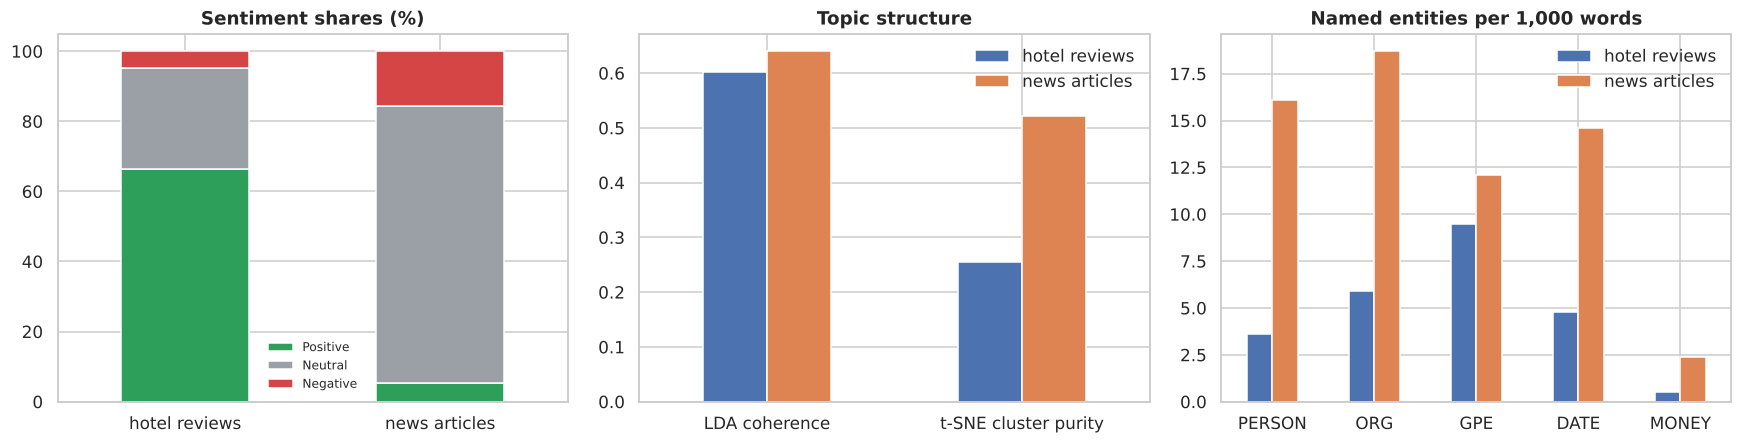

In [60]:
final = pd.DataFrame({
    "documents": [len(reviews), len(news)],
    "median length (words)": [int(reviews["n_words"].median()), int(news["n_words"].median())],
    "vocabulary (lemmas)": [len({w for t in reviews["tokens"] for w in t}), len({w for t in news["tokens"] for w in t})],
    "share Positive %": [sent_cmp.loc["Positive", "hotel reviews"], sent_cmp.loc["Positive", "news articles"]],
    "share Negative %": [sent_cmp.loc["Negative", "hotel reviews"], sent_cmp.loc["Negative", "news articles"]],
    "LDA coherence c_v (K=9)": [round(coh_rev, 3), round(fits[(K, best_seed)][1], 3)],
    "t-SNE silhouette (LDA topics)": [round(rep_rev["silhouette"], 3), round(rep_news["silhouette"], 3)],
    "t-SNE normalised 10-NN purity": [round(rep_rev["normalised purity"], 3), round(rep_news["normalised purity"], 3)],
    "named entities / 1,000 words": [round(ner_density["hotel reviews"].sum(), 1), round(ner_density["news articles"].sum(), 1)],
}, index=["hotel reviews", "news articles"]).T
display(final)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sent_cmp.T.plot(kind="bar", stacked=True, color=[SENT_COLORS[k] for k in ORDER], ax=axes[0], rot=0); axes[0].set_title("Sentiment shares (%)"); axes[0].legend(frameon=False, fontsize=8)
pd.DataFrame({"hotel reviews": [coh_rev, rep_rev["normalised purity"]], "news articles": [fits[(K, best_seed)][1], rep_news["normalised purity"]]},
             index=["LDA coherence", "t-SNE cluster purity"]).plot(kind="bar", ax=axes[1], rot=0); axes[1].set_title("Topic structure"); axes[1].legend(frameon=False)
ner_density.plot(kind="bar", ax=axes[2], rot=0); axes[2].set_title("Named entities per 1,000 words"); axes[2].legend(frameon=False)
plt.tight_layout(); save_fig("07_dataset_comparison"); plt.show()

## 7.1 What we found

| | Hotel reviews | News articles |
|---|---|---|
| Text | short (median 59 words), subjective, one domain | long (median 705 words), factual, 6 sections |
| Sentiment | informative: 66 % Positive / 29 % Neutral / 5 % Negative, agrees with rating groups | mostly Neutral (79 %): news is written in a neutral register, the tool detects hardly any sentiment; negative share (16 %) mostly reflects *topics* (war, crisis, sport defeats) rather than opinion |
| Topic modeling | topics are *aspects* (noise/windows, location/tube, value/service) — coherent (c_v 0.60) but heavily overlapping: reviews talk about the same aspects | topics are *themes* (c_v 0.64) that map well onto sections |
| t-SNE | weak structure (normalised purity 0.26, silhouette < 0) — the aspects overlap inside one review | clear structure (purity 0.52, silhouette 0.07); sport is a separate island |
| NER | 24 entities per 1,000 words; places (GPE) are the largest category, people are rare | 64 per 1,000 words, all five types occur regularly |

**Main conclusions**
1. **The kind of text decides which NLP tool is useful.** Sentiment analysis is meaningful for opinionated reviews and nearly empty for news; NER and entity linking are rich for news and thin for reviews; topic modeling and t-SNE work best on longer thematic documents.
2. **Preprocessing matters and must fit the task.** Lemmas without stop words are right for BoW/TF-IDF/LDA; the raw text is right for sentiment (negations) and NER (capital letters); BERT also needs the original text.
3. **Representation choice (Module 2).** On the reviews TF-IDF was the best of the three classic representations (macro-F1 0.88, vs 0.87 Word2Vec and 0.85 BoW), is interpretable and cheap; BERT adds semantic understanding (paraphrase, negation) at a much higher cost and is evaluated in the same table when its embeddings are computed.
4. **Sentiment scoring (Module 3).** Averaging VADER over sentences separates `4-5` from `1-3` reviews much better than scoring the whole review (AUC 0.89 vs 0.72), equal to TextBlob (0.91).
5. **Topic discovery (Module 4).** Nine topics, chosen by coherence, reproduce the editorial sections without labels and reveal finer themes (health research vs. space science; Labour vs. Reform-UK politics).
6. **Visual check (Module 5).** t-SNE showed that sport, economy and AI are well separated while science/environment topics overlap — information not visible in the keyword tables.
7. **Entities (Module 6).** NER on news yields thousands of mentions; entity linking merges variants (*Trump / Donald Trump*, *UK / Britain*) and disambiguates by context, but its coverage is limited by the size of the knowledge base (see 6.3) — the practical lesson is that **linking quality is a knowledge-base problem more than an algorithm problem**.

**Limitations and next steps** are listed in section 8.1.

---
# 8. Preparation for the defense — answers to the 14 questions
Each answer points to the place in this notebook where the idea is implemented.

**1. What is tokenization and why is it necessary?** Splitting a text into units (tokens: words, punctuation, sub-words). A computer sees a string of characters; every later step (stop words, lemmas, counting, embeddings) works on tokens. Module 1 (spaCy tokenizer); BERT uses its own *WordPiece* sub-word tokenizer.

**2. Stemming vs. lemmatization?** A stemmer cuts suffixes by rules (*studies → studi*), fast but crude, may give non-words. A lemmatizer uses a dictionary and part of speech to return the real base form (*studies → study, mice → mouse, was → be*). We use lemmatization (table in 1.5).

**3. Why do we remove stop words?** Words like *the, is, and* are the most frequent but carry little topical meaning; they inflate vectors and hide informative words. Removing them shrinks the vocabulary and sharpens BoW/TF-IDF/LDA. Exception: sentiment analysis keeps them (negations such as *not*), so Module 3 works on raw text.

**4. Bag of Words vs. TF-IDF?** BoW counts words; TF-IDF multiplies the count by the inverse document frequency, so words found in almost every document get low weight and distinctive words get high weight. Both ignore word order (section 2.1–2.2).

**5. How does Word2Vec represent words?** Each word is a dense vector (100 numbers) learned by predicting words from their neighbours (skip-gram). Words used in similar contexts get similar vectors, so distance/cosine measures semantic similarity; a document can be represented by the mean of its word vectors (section 2.3).

**6. Unigrams, bigrams, trigrams?** Sequences of 1, 2 or 3 consecutive tokens. Higher n restores some word order and phrases ("not clean", "tube station") at the cost of a much larger, sparser vocabulary (section 2.2, `ngram_range`).

**7. How does sentiment analysis determine the tone?** Our lexicon-based method (VADER) looks up the valence of each word in a human-rated dictionary and adjusts it with rules for negation, intensifiers, capitals, punctuation and "but"; the sentence scores are averaged and compared with thresholds. Machine-learning alternatives learn the mapping from labelled examples (Module 3).

**8. What is Latent Dirichlet Allocation?** A generative probabilistic model: each document is a mixture of topics (Dirichlet prior), each topic a distribution over words (Dirichlet prior). Given the word counts, inference finds topic-word and document-topic distributions that best explain the corpus (Module 4).

**9. How can LDA discover topics without predefined labels?** It is unsupervised: it only uses word co-occurrence. Words that tend to appear together in the same documents are pulled into the same topic; the topics are anonymous word distributions, and a human names them by reading the top words and example documents (4.4).

**10. What is a Word Cloud and what does it show?** A picture of words with size proportional to their weight (frequency or topic probability). It shows at a glance which words dominate a text/topic; it does not show relations between words or exact values (4.6).

**11. What is t-SNE and why is it used?** A non-linear dimensionality-reduction method that preserves *local neighbourhoods*; it maps high-dimensional document vectors to a 2-D plane so that similar documents are close, making clusters visible. Used for exploration and checking topic structure (Module 5); distances between clusters are not meaningful.

**12. What is Named Entity Recognition?** Detecting mentions of real-world entities in text and classifying them (PERSON, ORG, GPE, DATE, MONEY …). spaCy uses a neural network over token features (Module 6).

**13. NER vs. Entity Linking?** NER answers *"what kind of thing is this string?"*; Entity Linking answers *"which exact entity is it?"* by mapping the mention to a knowledge-base entry (ID, description, URL), resolving ambiguity (Washington) and merging variants (Trump / Donald Trump) (6.2–6.3).

**14. Limitations of the implemented system?** See the list below.

## 8.1 Limitations (answer to question 14)
* **Data.** Reviews come from one hotel; the `1-3` group spans 2004–2026 while `4-5` is mostly 2023–2026, and the class shares were assembled by us — so the reported sentiment shares do not describe the hotel's true distribution. Star ratings were restored as groups, not exact stars. News covers two autumn months of one newspaper; its topics reflect that period (e.g. the Burnham-related political stories).
* **Preprocessing.** The lemmatizer works on lowercased text, so part-of-speech decisions are sometimes wrong; stop-word removal drops negations (not used for sentiment, but it affects LDA/BoW).
* **Representations.** Word2Vec is trained on very small corpora; BERT is truncated to 256 word-pieces and is not directly interpretable.
* **Sentiment.** Lexicon-based: it misses sarcasm and domain meaning, and the Positive threshold was calibrated on rating groups (a mild form of tuning on the evaluation labels). "Neutral" mixes truly neutral and mixed reviews. News sentiment uses thresholds fitted on reviews.
* **LDA.** Needs the number of topics in advance, depends on the random start (we use 3 seeds), mixes themes in some topics, and one topic remains a "mixed" one; naming topics is subjective.
* **t-SNE.** Cluster distances and sizes are not meaningful; the picture depends on perplexity and the seed.
* **NER and linking.** The small spaCy model makes mistakes on UK-specific and recent names and tags the same string differently in different contexts; no gold annotations, so quality is estimated from a small manual check. Our knowledge base is small and hand-made — mentions outside it stay unlinked unless Wikidata is reachable; the context rule is crude (keyword overlap).

**Possible improvements.** more hotels/years and exact star ratings; a supervised or transformer-based sentiment model; coherence-based and hierarchical topic models (or BERTopic); `en_core_web_trf` for NER and a learned entity linker (e.g. BLINK) with the full Wikidata/Wikipedia KB.

---
# 9. Sources and academic integrity
**Data.**
* Dataset 1: TripAdvisor reviews of *Phoenix Hotel, London* (tripadvisor.co.uk), collected in November 2026 with the Easy Scraper browser extension; personal data removed (see `data/DATASET_DESCRIPTION.md`).
* Dataset 2: The Guardian Open Platform API, https://open-platform.theguardian.com/ — content © Guardian News & Media Ltd, used for educational purposes.

**Libraries.** pandas, NumPy, matplotlib, seaborn, scikit-learn (CountVectorizer, TF-IDF, LDA, t-SNE, metrics), spaCy and `en_core_web_sm` (tokenization, lemmatization, NER), NLTK (Porter stemmer for the comparison only), gensim (Word2Vec, coherence),
Hugging Face Transformers + PyTorch (`bert-base-uncased`), vaderSentiment, TextBlob, wordcloud, rapidfuzz, pycountry, requests (Wikidata API).

**Literature / references.** Blei, Ng, Jordan (2003) *Latent Dirichlet Allocation*; Mikolov et al. (2013) *Word2Vec*; Devlin et al. (2019) *BERT*; Hutto & Gilbert (2014) *VADER*; van der Maaten & Hinton (2008) *t-SNE*; Röder, Both, Hinneburg (2015) *Exploring the space of topic coherence measures*.

**Suggested practical references given in the assignment** (the Kaggle notebooks on TripAdvisor LDA and CORD-19) were consulted only as general orientation; no code or text from them was copied. The data collection, preprocessing function, thresholds, the topic-count selection with coherence,
topic naming, the cluster-quality measures, the dataset comparison and the entity-linking method were written for this project.